# Will it rain tomorrow? Ensemble learning across Sri Lanka's climatic zones
**CM3720 Machine Learning & Pattern Recognition, hands-on project (ensemble learning dashboard)**
**224220D, Wimalasuriya A.G.A.B.**

| | |
|---|---|
| Question | Will it rain 1 mm or more tomorrow in a Sri Lankan city? (also compared with 5 mm or more) |
| Data | Daily ERA5 reanalysis weather, 9 Sri Lankan cities, 2010-01-01 to 2026-11-15. Weather data by Open-Meteo.com (CC BY 4.0) |
| Ensembles | Bagging (Random Forest), Boosting (XGBoost, LightGBM, CatBoost), Stacking, Voting, Hybrid (ARIMA + RF) |
| Explainability | Feature importance, SHAP, comparison between wet / intermediate / dry zones |
| Dashboard | Streamlit app with a Sri Lanka map and live Open-Meteo data (see GitHub repo) |

### AI-use declaration
AI tools (Claude) were used to write all of the code and its comments (this notebook, the Streamlit dashboard and
the scripts that draw the charts and images), and to help with the wording of my written sections (the points and
decisions in them are my own). The project idea, the choice of data and cities, the planning, the modelling decisions, and the
plan and Excalidraw-style look of the architecture diagram are my own. I reviewed the code and the results,
and I take responsibility for the submitted work.

## 1. My idea and motivation
My final year project is about flood early warning for the Kelani river, so knowing about heavy rain early
is important to me. Rain also matters a lot for farmers in Sri Lanka, because the Yala and Maha seasons depend
on it. So I wanted to see how well ensemble models can predict whether it will rain tomorrow.

Sri Lanka is a small country, but the rain is very different from place to place. In my data Ratnapura gets
about 4,400 mm a year and Jaffna only about 1,300 mm. The monsoons also bring rain to each zone at different
times of the year. So I wanted to check if one model works equally well for the wet, intermediate and dry zones.

**Research questions**
1. Which ensemble works best (bagging, boosting or stacking), and how much better is it than simple guesses?
2. Is rain harder to predict in some zones than in others? Why?
3. Is light rain (1 mm or more) or real rain (5 mm or more) harder to predict?
4. Do the hybrids (ARIMA + Random Forest and Random Forest + ANN) help?

**What I expect before modelling**
I think boosting (XGBoost) will be the best, because each new tree fixes the mistakes of the earlier trees, but I
think the difference from Random Forest and stacking will be small. I also think the intermediate zone will be the
hardest, because it rains on a little more than half of the days there and both monsoons and the hills affect it.

## 2. Data
- Source: Open-Meteo Historical Weather API, model ERA5 (ECMWF / Copernicus reanalysis, ~25 km grid)
- Downloaded with `src/download_data.py`: 9 cities, daily, 2010-01-01 to 2026-11-15

I picked cities from every part of the island: the south-west coast (Colombo, Galle), Ratnapura, the hills
(Kandy, Nuwara Eliya, Badulla) and the north and east (Jaffna, Anuradhapura, Trincomalee). This gives at least two
cities in every zone, so the zones can be compared. I also added Nuwara Eliya because it is the highest place
(1,868 m), to see if height has an effect on rain.

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42

raw = pd.read_csv("data/raw/sl_weather_era5_daily.csv", parse_dates=["date"])
print(raw.shape)
raw.head()

(55467, 20)


,city,date,temperature_2m_max,temperature_2m_min,temperature_2m_mean,relative_humidity_2m_mean,dew_point_2m_mean,pressure_msl_mean,cloud_cover_mean,precipitation_sum,rain_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,shortwave_radiation_sum,et0_fao_evapotranspiration,grid_lat,grid_lon,elevation
0,Colombo,2010-01-01,31.5,23.0,26.7,74,21.6,1009.8,73,0.0,0.0,0.0,17.9,37.8,20,21.02,5.01,7.0,80.0,3.0
1,Colombo,2010-01-02,30.8,23.5,26.9,75,22.0,1011.3,64,0.0,0.0,0.0,17.7,36.0,19,17.98,4.32,7.0,80.0,3.0
2,Colombo,2010-01-03,31.3,24.0,26.8,79,22.8,1011.8,74,0.2,0.2,1.0,16.6,34.9,17,18.05,4.08,7.0,80.0,3.0
3,Colombo,2010-01-04,29.7,23.7,26.1,76,21.5,1010.9,58,0.0,0.0,0.0,18.2,38.2,5,18.46,4.21,7.0,80.0,3.0
4,Colombo,2010-01-05,29.5,20.3,24.8,72,19.1,1009.4,26,0.0,0.0,0.0,17.4,36.0,1,23.54,5.16,7.0,80.0,3.0


### 2.1 Data quality checks

In [2]:
print("cities:", raw.city.nunique(), "| dates:", raw.date.min().date(), "->", raw.date.max().date())
print("days per city:", raw.groupby("city").size().unique())
print("missing values:", int(raw.isna().sum().sum()), "| duplicate (city, date) rows:", int(raw.duplicated(["city", "date"]).sum()))
raw.drop(columns=["city", "date"]).describe().T.round(1)

cities: 9 | dates: 2010-01-01 -> 2026-11-15
days per city: [6163]
missing values: 0 | duplicate (city, date) rows: 0


,count,mean,std,min,25%,50%,75%,max
temperature_2m_max,55467.0,29.0,3.8,12.8,27.9,29.8,31.3,37.9
temperature_2m_min,55467.0,23.1,4.0,6.8,21.8,24.3,25.6,30.5
temperature_2m_mean,55467.0,25.6,3.7,11.0,25.0,26.7,27.8,31.5
relative_humidity_2m_mean,55467.0,82.3,7.7,42.0,78.0,84.0,88.0,99.0
dew_point_2m_mean,55467.0,22.2,3.5,2.5,21.2,23.4,24.6,27.7
pressure_msl_mean,55467.0,1010.7,2.3,1001.2,1009.2,1010.8,1012.3,1019.0
cloud_cover_mean,55467.0,74.6,24.2,0.0,59.0,82.0,95.0,100.0
precipitation_sum,55467.0,6.3,11.7,0.0,0.2,2.1,7.5,265.0
rain_sum,55467.0,6.3,11.7,0.0,0.2,2.1,7.5,265.0
precipitation_hours,55467.0,8.2,7.4,0.0,1.0,7.0,13.0,24.0


### 2.2 ERA5 grid points used for each city (nearest 0.25° grid cell)

In [3]:
loc = raw.groupby("city")[["grid_lat", "grid_lon", "elevation"]].first()
loc

,grid_lat,grid_lon,elevation
city,,,
Anuradhapura,8.25,80.50,93.0
Badulla,7.00,81.00,662.0
Colombo,7.00,80.00,3.0
Galle,6.25,80.25,0.0
Jaffna,9.75,80.00,8.0
Kandy,7.25,80.75,518.0
Nuwara Eliya,7.00,80.75,1868.0
Ratnapura,6.75,80.50,27.0
Trincomalee,8.50,81.25,14.0


## 3. Exploratory data analysis
### 3.1 Climatic zones from mean annual rainfall (training years 2010 to 2021)
Wet: more than 2,500 mm. Intermediate: 1,750 to 2,500 mm. Dry: less than 1,750 mm.

Different sources do not agree on the zone of some cities, for example Kandy. So I did not copy a list. I used
the real yearly rainfall of each city to decide its zone. I only used the training years (2010 to 2021), so
nothing from the test years is used (no data leakage). One interesting thing: Colombo gets 2,526 mm, so it is only
just above the wet zone limit of 2,500 mm.

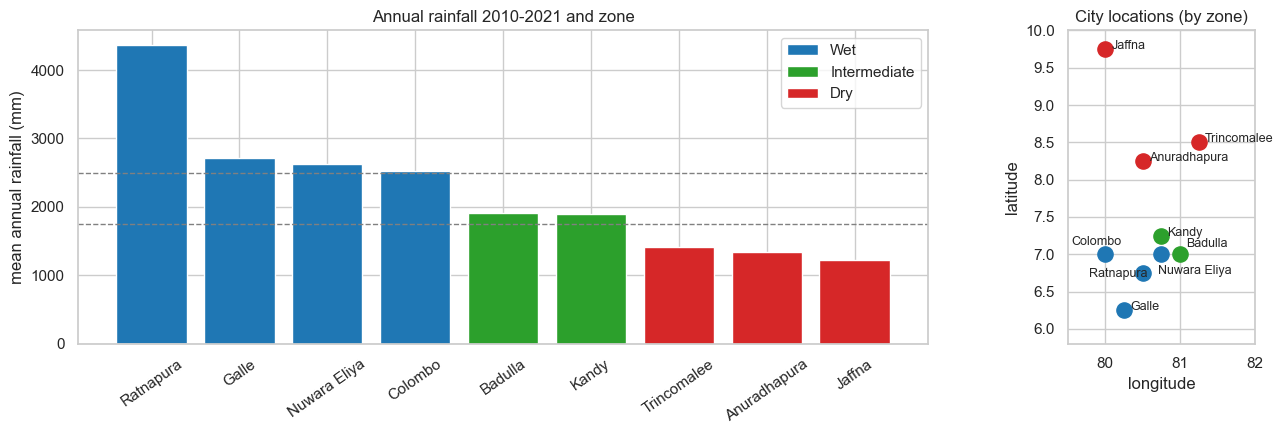

,annual_rain_mm,zone
Ratnapura,4361.0,Wet
Galle,2713.0,Wet
Nuwara Eliya,2621.0,Wet
Colombo,2526.0,Wet
Badulla,1915.0,Intermediate
Kandy,1892.0,Intermediate
Trincomalee,1416.0,Dry
Anuradhapura,1334.0,Dry
Jaffna,1227.0,Dry


In [4]:
TRAIN_END, VALID_END = "2021-12-31", "2023-12-31"
tr = raw[raw.date <= TRAIN_END]
annual = tr.groupby(["city", tr.date.dt.year]).precipitation_sum.sum().groupby("city").mean().sort_values(ascending=False)
def zone_of(mm): return "Wet" if mm > 2500 else ("Intermediate" if mm >= 1750 else "Dry")
ZONE = annual.apply(zone_of).to_dict()
ZONE_COLORS = {"Wet": "#1f77b4", "Intermediate": "#2ca02c", "Dry": "#d62728"}

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [2, 1]})
ax[0].bar(annual.index, annual.values, color=[ZONE_COLORS[ZONE[c]] for c in annual.index])
for y in (1750, 2500): ax[0].axhline(y, ls="--", c="grey", lw=1)
ax[0].set_ylabel("mean annual rainfall (mm)"); ax[0].set_title("Annual rainfall 2010-2021 and zone"); ax[0].tick_params(axis="x", rotation=35)
for z, c in ZONE_COLORS.items(): ax[0].bar(0, 0, color=c, label=z)
ax[0].legend()
OFFSET = {"Colombo": (-0.45, 0.12), "Nuwara Eliya": (-0.05, -0.27), "Badulla": (0.08, 0.1), "Ratnapura": (-0.72, -0.05)}   # label positions so names don't overlap
for c, r in loc.iterrows():
    dx, dy = OFFSET.get(c, (0.08, 0.0))
    ax[1].scatter(r.grid_lon, r.grid_lat, s=120, color=ZONE_COLORS[ZONE[c]]); ax[1].annotate(c, (r.grid_lon + dx, r.grid_lat + dy), fontsize=9)
ax[1].set_xlim(79.5, 82); ax[1].set_ylim(5.8, 10); ax[1].set_aspect("equal"); ax[1].set_title("City locations (by zone)")
ax[1].set_xlabel("longitude"); ax[1].set_ylabel("latitude")
plt.tight_layout(); plt.savefig("images/zones.png", dpi=120, bbox_inches="tight"); plt.show()
pd.DataFrame({"annual_rain_mm": annual.round(0), "zone": pd.Series(ZONE)})

### 3.2 Monthly rainfall by zone and monsoon season
Seasons (Dept. of Census & Statistics): first inter-monsoon (Mar, Apr), south-west (May to Sep), second inter-monsoon (Oct, Nov), north-east (Dec to Feb)

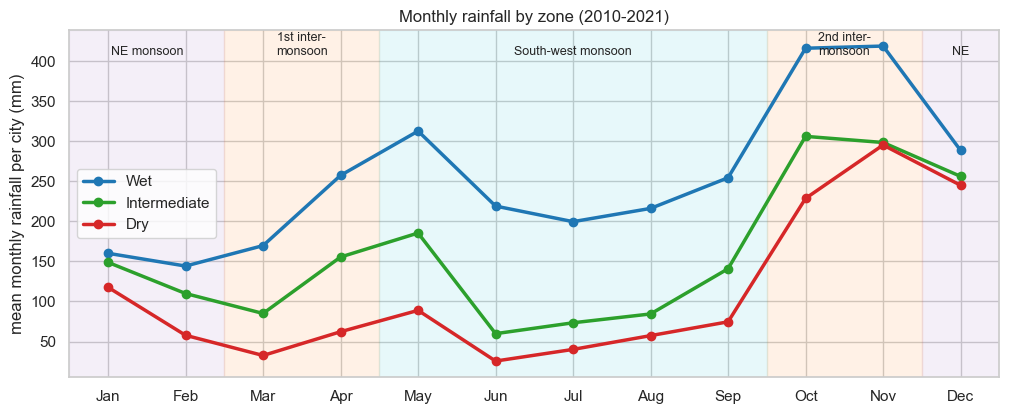

m,1,2,3,4,5,6,7,8,9,10,11,12
zone,,,,,,,,,,,,
Dry,118.0,58.0,33.0,62.0,89.0,26.0,40.0,57.0,75.0,229.0,295.0,245.0
Intermediate,149.0,110.0,85.0,155.0,185.0,60.0,73.0,84.0,141.0,306.0,298.0,256.0
Wet,160.0,144.0,170.0,257.0,313.0,219.0,200.0,216.0,254.0,416.0,419.0,288.0


In [5]:
raw["zone"] = raw.city.map(ZONE)
monthly =(raw[raw.date <= TRAIN_END].assign(y=raw.date.dt.year, m=raw.date.dt.month)
           .groupby(["zone", "city", "y", "m"]).precipitation_sum.sum().groupby(["zone", "m"]).mean().unstack(0))
fig, ax = plt.subplots(figsize=(12, 4.5))
for z in ["Wet", "Intermediate", "Dry"]: ax.plot(monthly.index, monthly[z], marker="o", lw=2.5, color=ZONE_COLORS[z], label=z)
top = ax.get_ylim()[1]
for a, b, name, col in [(0.5, 2.5, "NE monsoon", "#9467bd"), (2.5, 4.5, "1st inter-\nmonsoon", "#ff7f0e"),
                        (4.5, 9.5, "South-west monsoon", "#17becf"), (9.5, 11.5, "2nd inter-\nmonsoon", "#ff7f0e"),
                        (11.5, 12.5, "NE", "#9467bd")]:
    ax.axvspan(a, b, alpha=0.10, color=col); ax.text((a + b) / 2, top * 0.93, name, ha="center", fontsize=9)
ax.set_xlim(0.5, 12.5)
ax.set_xticks(range(1, 13)); ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_ylabel("mean monthly rainfall per city (mm)"); ax.set_title("Monthly rainfall by zone (2010-2021)"); ax.legend()
plt.savefig("images/monsoon_by_zone.png", dpi=120, bbox_inches="tight"); plt.show()
monthly.round(0).T

### 3.3 Share of days above each rain threshold
Targets: 1 mm or more of rain tomorrow (main target, the ETCCDI "wet day" definition R1mm) and 5 mm or more (compared later)

In the ERA5 data about 79% of days have a tiny bit of rain (0.1 mm or more). That does not happen in real life.
Reanalysis models give small drizzle on too many days, so I needed a threshold. I used 1 mm because it is the
"wet day" definition used in international climate indices (ETCCDI R1mm). I also used 5 mm, which is real rain
that you need an umbrella for. Heavier rain is also what matters for floods, which links to my final year project.

In [6]:
thr = pd.DataFrame({f">= {t} mm": raw.groupby("city").precipitation_sum.apply(lambda s, t=t: (s >= t).mean())
                    for t in (0.1, 1, 5)}).loc[annual.index]
thr.loc["ALL CITIES"] = [(raw.precipitation_sum >= t).mean() for t in (0.1, 1, 5)]
(thr * 100).round(0).astype(int).astype(str) + " %"

,>= 0.1 mm,>= 1 mm,>= 5 mm
city,,,
Ratnapura,96 %,88 %,55 %
Galle,92 %,82 %,48 %
Nuwara Eliya,85 %,74 %,43 %
Colombo,86 %,74 %,41 %
Badulla,74 %,54 %,30 %
Kandy,79 %,60 %,27 %
Trincomalee,65 %,40 %,19 %
Anuradhapura,76 %,48 %,21 %
Jaffna,58 %,38 %,17 %


## 4. Feature engineering
Features use data up to day *t*; the target is day *t+1*. Saved to `src/features.py` (also used by the dashboard).

| Group | Features |
|---|---|
| Today's weather | temperature max/min/mean and range, humidity, dew point, pressure, cloud cover, rain, rain hours, wind speed/gust, wind direction (sin/cos), sunshine radiation, evapotranspiration |
| Recent history | rain yesterday and 2 days ago, rain over the last 3 and 7 days, wet days in the last 7, change in pressure / humidity / temperature since yesterday |
| Calendar | month and day-of-year as sin/cos, monsoon season (4 seasons) |
| Place | zone (wet / intermediate / dry), city, elevation |

In [7]:
%%writefile src/features.py
"""Features for next-day rain. Used by the notebook and the dashboard."""
import numpy as np
import pandas as pd

WEATHER = ["temperature_2m_max", "temperature_2m_min", "temperature_2m_mean", "relative_humidity_2m_mean",
           "dew_point_2m_mean", "pressure_msl_mean", "cloud_cover_mean", "precipitation_sum", "precipitation_hours",
           "wind_speed_10m_max", "wind_gusts_10m_max", "shortwave_radiation_sum", "et0_fao_evapotranspiration"]
SEASONS = ["First inter-monsoon", "South-west monsoon", "Second inter-monsoon", "North-east monsoon"]
ZONES = ["Wet", "Intermediate", "Dry"]


def season_of(month):
    if month in (3, 4): return SEASONS[0]
    if 5 <= month <= 9: return SEASONS[1]
    if month in (10, 11): return SEASONS[2]
    return SEASONS[3]


def make_features(df, zone_map, cities):
    """One row per city per day, using only that day and earlier days."""
    out = []
    for city, g in df.sort_values("date").groupby("city", sort=False):
        g = g.copy()
        r = g["precipitation_sum"]
        g["temp_range"] = g["temperature_2m_max"] - g["temperature_2m_min"]
        g["rain_lag1"], g["rain_lag2"] = r.shift(1), r.shift(2)
        g["rain_3d"], g["rain_7d"] = r.rolling(3).sum(), r.rolling(7).sum()
        g["wet_days_7d"] = (r >= 1).rolling(7).sum()
        for col, name in [("pressure_msl_mean", "pressure"), ("relative_humidity_2m_mean", "humidity"),
                          ("temperature_2m_mean", "temp")]:
            g[f"{name}_change"] = g[col].diff()
        wd = np.deg2rad(g["wind_direction_10m_dominant"])
        g["wind_dir_sin"], g["wind_dir_cos"] = np.sin(wd), np.cos(wd)
        m, doy = g["date"].dt.month, g["date"].dt.dayofyear
        g["month_sin"], g["month_cos"] = np.sin(2 * np.pi * m / 12), np.cos(2 * np.pi * m / 12)
        g["doy_sin"], g["doy_cos"] = np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25)
        g["season"] = m.map(season_of)
        g["zone"] = zone_map[city]
        out.append(g)
    f = pd.concat(out, ignore_index=True)
    for s in SEASONS: f[f"season_{s}"] = (f["season"] == s).astype(int)
    for z in ZONES: f[f"zone_{z}"] = (f["zone"] == z).astype(int)
    for c in cities: f[f"city_{c}"] = (f["city"] == c).astype(int)
    return f


def feature_columns(cities):
    return (WEATHER + ["elevation", "temp_range", "rain_lag1", "rain_lag2", "rain_3d", "rain_7d", "wet_days_7d",
                       "pressure_change", "humidity_change", "temp_change", "wind_dir_sin", "wind_dir_cos",
                       "month_sin", "month_cos", "doy_sin", "doy_cos"]
            + [f"season_{s}" for s in SEASONS] + [f"zone_{z}" for z in ZONES] + [f"city_{c}" for c in cities])


def fourier(dates, K=2):
    """Yearly seasonal terms used by the ARIMA model."""
    doy = pd.to_datetime(pd.Series(dates)).dt.dayofyear.values
    return np.column_stack([f(2 * np.pi * k * doy / 365.25) for k in range(1, K + 1) for f in (np.sin, np.cos)])


def add_targets(f):
    """Rain on the next day for each city."""
    f = f.sort_values(["city", "date"]).copy()
    f["rain_tomorrow_mm"] = f.groupby("city")["precipitation_sum"].shift(-1)
    f["rain_tomorrow_1mm"] = (f["rain_tomorrow_mm"] >= 1).astype("float").where(f["rain_tomorrow_mm"].notna())
    f["rain_tomorrow_5mm"] = (f["rain_tomorrow_mm"] >= 5).astype("float").where(f["rain_tomorrow_mm"].notna())
    return f

Overwriting src/features.py


In [8]:
from src.features import make_features, feature_columns, add_targets
CITIES = sorted(raw.city.unique())
FEATURES = feature_columns(CITIES)

data = add_targets(make_features(raw, ZONE, CITIES))
data = data.dropna(subset=FEATURES + ["rain_tomorrow_mm"]).reset_index(drop=True)   # drops first 6 days and last day of each city
print("rows:", len(data), "| features:", len(FEATURES))
data[["city", "date", "zone", "season", "precipitation_sum", "rain_7d", "rain_tomorrow_mm", "rain_tomorrow_1mm"]].head(8)

rows: 55404 | features: 45


,city,date,zone,season,precipitation_sum,rain_7d,rain_tomorrow_mm,rain_tomorrow_1mm
0,Anuradhapura,2010-01-07,Dry,North-east monsoon,1.7,3.1,31.8,1.0
1,Anuradhapura,2010-01-08,Dry,North-east monsoon,31.8,34.9,1.6,1.0
2,Anuradhapura,2010-01-09,Dry,North-east monsoon,1.6,36.5,0.4,0.0
3,Anuradhapura,2010-01-10,Dry,North-east monsoon,0.4,35.5,0.7,0.0
4,Anuradhapura,2010-01-11,Dry,North-east monsoon,0.7,36.2,7.8,1.0
5,Anuradhapura,2010-01-12,Dry,North-east monsoon,7.8,44.0,2.5,1.0
6,Anuradhapura,2010-01-13,Dry,North-east monsoon,2.5,46.5,1.0,1.0
7,Anuradhapura,2010-01-14,Dry,North-east monsoon,1.0,45.8,0.0,0.0


### 4.1 Time-based split

| Split | Period | Use |
|---|---|---|
| Train | 2010 to 2021 | fit the models |
| Validation | 2022 to 2023 | choose hyper-parameters, train the stacking meta-model |
| Test | 2024 to Nov 2026 | final evaluation |

Weather today and tomorrow is usually very similar. With a random split, the day next to a test day could be in
the training data, and the score would look better than it really is (data leakage). In real life we use the past
to predict the future, so the split does the same. Every split has full years, so all four monsoon seasons are in
each one. The validation years (2022 and 2023) were wetter than normal: it rained on 69% of days compared to 61% in
training. So the weather changes from year to year.

In [9]:
train = data[data.date <= TRAIN_END]
valid = data[(data.date > TRAIN_END) & (data.date <= VALID_END)]
test = data[data.date > VALID_END]
split = pd.DataFrame({name: {"rows": len(d), "from": d.date.min().date(), "to": d.date.max().date(),
                             "rain >= 1 mm tomorrow": f"{d.rain_tomorrow_1mm.mean():.1%}",
                             "rain >= 5 mm tomorrow": f"{d.rain_tomorrow_5mm.mean():.1%}"}
                      for name, d in [("train", train), ("valid", valid), ("test", test)]}).T
split

,rows,from,to,rain >= 1 mm tomorrow,rain >= 5 mm tomorrow
train,39393,2010-01-07,2021-12-31,61.1%,33.1%
valid,6570,2022-01-01,2023-12-31,68.8%,37.2%
test,9441,2024-01-01,2026-11-14,61.9%,31.3%


### 4.2 Correlation of each feature with rain tomorrow

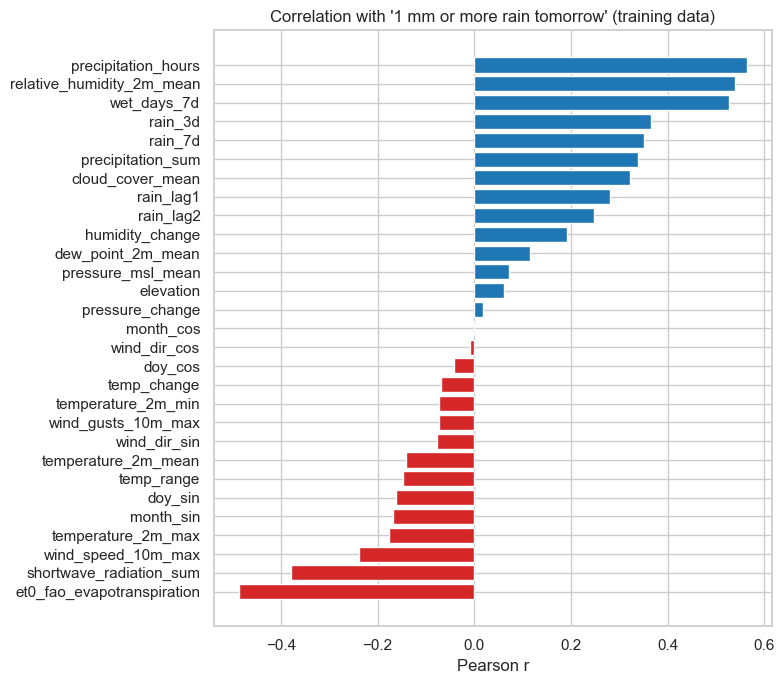

In [10]:
num = [c for c in FEATURES if not c.startswith(("city_", "zone_", "season_"))]
corr = train[num + ["rain_tomorrow_1mm"]].corr()["rain_tomorrow_1mm"].drop("rain_tomorrow_1mm").sort_values()
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(corr.index, corr.values, color=["#d62728" if v < 0 else "#1f77b4" for v in corr.values])
ax.set_title("Correlation with '1 mm or more rain tomorrow' (training data)"); ax.set_xlabel("Pearson r"); plt.tight_layout(); plt.show()

**What I see in the charts**
- Monsoon chart: the wet zone has two peaks, in May (south-west monsoon) and in October to November. The dry zone gets
  most of its rain from October to December, and it is very dry from June to August. The intermediate zone is in
  between the two.
- Correlation chart: when today has more hours of rain, higher humidity and more wet days in the last week, rain
  tomorrow is more likely. More sunshine and evaporation make rain tomorrow less likely. This makes sense, because
  wet weather usually lasts a few days in a row.
- A trap I found: in the wet zone it rains on about 80% of days, so a model that always says "rain" would already get
  about 80% accuracy. So accuracy alone cannot be used to compare the zones. I will use balanced accuracy, F1 and
  ROC-AUC instead.

## 5. Models
All models are trained on 2010 to 2021, tuned on 2022 to 2023 (validation) and tested once on 2024 to Nov 2026.
Main target: 1 mm or more of rain tomorrow.

In [11]:
import time
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score, brier_score_loss,
                             roc_curve)
from sklearn.model_selection import ParameterGrid

TARGET = "rain_tomorrow_1mm"
Xtr, ytr = train[FEATURES], train[TARGET].astype(int)
Xva, yva = valid[FEATURES], valid[TARGET].astype(int)
Xte, yte = test[FEATURES], test[TARGET].astype(int)

def scores(y, prob, thr=0.5):
    pred = (prob >= thr).astype(int)
    return {"accuracy": accuracy_score(y, pred), "balanced_acc": balanced_accuracy_score(y, pred),
            "F1": f1_score(y, pred), "ROC_AUC": roc_auc_score(y, prob), "Brier": brier_score_loss(y, prob)}

RESULTS, TEST_PROB, INFO = {}, {}, {}
def record(name, prob_test, group, seconds=None, params=None):
    TEST_PROB[name] = np.asarray(prob_test)
    RESULTS[name] = {"group": group, **scores(yte, TEST_PROB[name]),
                     "train_s": None if seconds is None else round(seconds, 1)}
    if params is not None: INFO[name] = params

### 5.1 Baselines (no machine learning)
- Climatology: the chance of rain for that city in the training years (always predicts the usual answer)
- Persistence: tomorrow will be the same as today

In [12]:
clim = train.groupby("city")[TARGET].mean()
record("Baseline: climatology", test.city.map(clim).values, "Baseline")
record("Baseline: persistence", (test.precipitation_sum >= 1).astype(float).values, "Baseline")
pd.DataFrame(RESULTS).T.drop(columns="train_s")

,group,accuracy,balanced_acc,F1,ROC_AUC,Brier
Baseline: climatology,Baseline,0.672386,0.640711,0.745159,0.712513,0.20443
Baseline: persistence,Baseline,0.794619,0.782176,0.834146,0.782176,0.205381


### 5.2 Single decision tree and the ensembles
Hyper-parameters are chosen by the best ROC-AUC on the validation years.

In [13]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier, AdaBoostClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

def tune(name, group, make, grid):
    best = None
    t0 = time.time()
    for params in ParameterGrid(grid):
        m = make(**params).fit(Xtr, ytr)
        auc = roc_auc_score(yva, m.predict_proba(Xva)[:, 1])
        if best is None or auc > best[0]: best = (auc, params, m)
    auc, params, model = best
    record(name, model.predict_proba(Xte)[:, 1], group, time.time() - t0, {**params, "valid_AUC": round(auc, 4)})
    print(f"{name:22s} best {params}  valid AUC {auc:.4f}")
    return model

MODELS = {}
MODELS["Decision tree"] = tune("Decision tree", "Single tree",
    lambda **p: DecisionTreeClassifier(random_state=RANDOM_STATE, **p),
    {"max_depth": [4, 6, 8, 10], "min_samples_leaf": [20, 50]})
MODELS["Bagging (trees)"] = tune("Bagging (trees)", "Bagging",
    lambda **p: BaggingClassifier(DecisionTreeClassifier(min_samples_leaf=5), n_estimators=100, n_jobs=-1,
                                  random_state=RANDOM_STATE, **p),
    {"max_samples": [0.5, 1.0]})
MODELS["Random Forest"] = tune("Random Forest", "Bagging",
    lambda **p: RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE, **p),
    {"max_depth": [None, 15], "min_samples_leaf": [1, 5], "max_features": ["sqrt", 0.5]})
MODELS["AdaBoost"] = tune("AdaBoost", "Boosting",
    lambda **p: AdaBoostClassifier(random_state=RANDOM_STATE, **p),
    {"n_estimators": [300], "learning_rate": [0.5, 1.0]})
MODELS["XGBoost"] = tune("XGBoost", "Boosting",
    lambda **p: XGBClassifier(n_estimators=400, subsample=0.8, colsample_bytree=0.8, eval_metric="logloss",
                              n_jobs=-1, random_state=RANDOM_STATE, **p),
    {"learning_rate": [0.05, 0.1], "max_depth": [4, 6]})
MODELS["LightGBM"] = tune("LightGBM", "Boosting",
    lambda **p: LGBMClassifier(n_estimators=400, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                               random_state=RANDOM_STATE, verbose=-1, **p),
    {"learning_rate": [0.05, 0.1], "num_leaves": [31, 63]})
MODELS["CatBoost"] = tune("CatBoost", "Boosting",
    lambda **p: CatBoostClassifier(allow_writing_files=False, iterations=500, verbose=0, random_seed=RANDOM_STATE, thread_count=-1, **p),
    {"learning_rate": [0.05, 0.1], "depth": [4, 6]})

Decision tree          best {'max_depth': 6, 'min_samples_leaf': 50}  valid AUC 0.8698


Bagging (trees)        best {'max_samples': 0.5}  valid AUC 0.8861


Random Forest          best {'max_depth': 15, 'max_features': 'sqrt', 'min_samples_leaf': 5}  valid AUC 0.8898


AdaBoost               best {'learning_rate': 1.0, 'n_estimators': 300}  valid AUC 0.8853


XGBoost                best {'learning_rate': 0.05, 'max_depth': 4}  valid AUC 0.8891


LightGBM               best {'learning_rate': 0.05, 'num_leaves': 31}  valid AUC 0.8874


CatBoost               best {'depth': 6, 'learning_rate': 0.05}  valid AUC 0.8916


### 5.3 Random Forest out-of-bag (OOB) score
Each tree is trained on a bootstrap sample, so about a third of the training rows are left out of each tree.
Those rows give a free estimate of accuracy without a separate test set.

In [14]:
rf_params = {k: v for k, v in INFO["Random Forest"].items() if k != "valid_AUC"}
rf_oob = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE, oob_score=True, **rf_params).fit(Xtr, ytr)
print(f"OOB accuracy (training years): {rf_oob.oob_score_:.3f}")
print(f"Test accuracy (2024-2026):     {RESULTS['Random Forest']['accuracy']:.3f}")

OOB accuracy (training years): 0.816
Test accuracy (2024-2026):     0.811


### 5.3b How many trees are needed?
The Random Forest's prediction is the average of its trees. Here the average is taken over the first *n* trees only,
for growing *n*, and scored on the validation and test years.

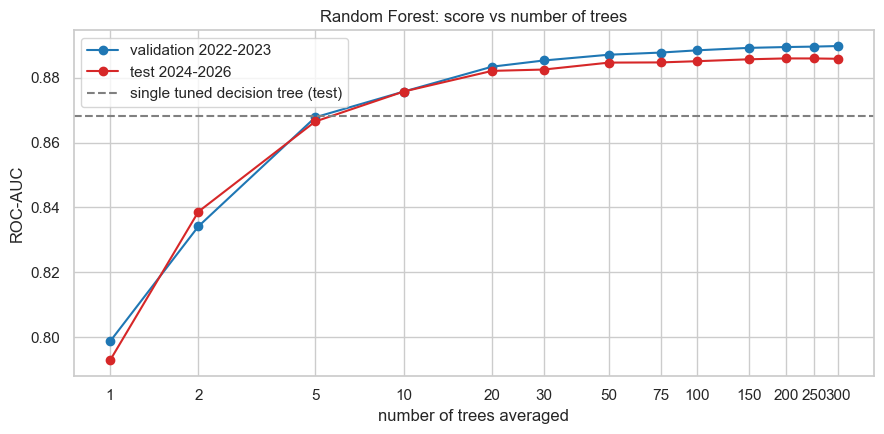

number of trees,1,2,5,10,20,30,50,75,100,150,200,250,300
validation 2022-2023,0.7986,0.8341,0.8678,0.8757,0.8834,0.8853,0.8871,0.8878,0.8885,0.8892,0.8895,0.8896,0.8898
test 2024-2026,0.7928,0.8387,0.8665,0.8757,0.8821,0.8825,0.8847,0.8847,0.8851,0.8857,0.8860,0.8859,0.8858


In [15]:
rf = MODELS["Random Forest"]
def tree_curve(X, y, sizes):
    probs = np.array([t.predict_proba(X.values)[:, 1] for t in rf.estimators_])      # one row per tree
    running = np.cumsum(probs, axis=0) / np.arange(1, len(probs) + 1)[:, None]      # average of the first n trees
    return [roc_auc_score(y, running[n - 1]) for n in sizes]
SIZES = [1, 2, 5, 10, 20, 30, 50, 75, 100, 150, 200, 250, 300]
curve = pd.DataFrame({"validation 2022-2023": tree_curve(Xva, yva, SIZES), "test 2024-2026": tree_curve(Xte, yte, SIZES)},
                     index=pd.Index(SIZES, name="number of trees"))
fig, ax = plt.subplots(figsize=(9, 4.5))
for c, col in zip(curve.columns, ["#1f77b4", "#d62728"]):
    ax.plot(curve.index, curve[c], marker="o", color=col, label=c)
ax.axhline(RESULTS["Decision tree"]["ROC_AUC"], ls="--", color="grey", label="single tuned decision tree (test)")
ax.set_xscale("log"); ax.set_xticks(SIZES); ax.set_xticklabels(SIZES)
ax.set_xlabel("number of trees averaged"); ax.set_ylabel("ROC-AUC"); ax.set_title("Random Forest: score vs number of trees")
ax.legend(); plt.tight_layout(); plt.savefig("images/trees_curve.png", dpi=120, bbox_inches="tight"); plt.show()
curve.round(4).T

### 5.4 Voting and stacking
- Soft voting: the average of the rain probabilities of Random Forest, XGBoost, LightGBM and CatBoost
- Stacking: a logistic regression (meta-model) learns how to combine the base models. It is trained on the base
  models' predictions for the validation years, so it never sees the test years.

In [16]:
from sklearn.linear_model import LogisticRegression
BASE = ["Random Forest", "Bagging (trees)", "XGBoost", "LightGBM", "CatBoost"]
VOTE = ["Random Forest", "XGBoost", "LightGBM", "CatBoost"]

record("Soft voting", np.mean([MODELS[m].predict_proba(Xte)[:, 1] for m in VOTE], axis=0), "Voting")

Pva = np.column_stack([MODELS[m].predict_proba(Xva)[:, 1] for m in BASE])
Pte = np.column_stack([MODELS[m].predict_proba(Xte)[:, 1] for m in BASE])
meta = LogisticRegression(max_iter=1000).fit(Pva, yva)
record("Stacking", meta.predict_proba(Pte)[:, 1], "Stacking")
pd.Series(meta.coef_[0], index=BASE, name="meta-model weight").round(3)

Random Forest      2.270
Bagging (trees)    0.605
XGBoost            0.365
LightGBM           0.181
CatBoost           2.426
Name: meta-model weight, dtype: float64

### 5.5 Hybrid: ARIMA + Random Forest
For each city an ARIMA(2,0,1) model with yearly seasonal terms is fitted on the training years to log(1 + rain).
Its forecast for tomorrow is added as one more feature to the Random Forest.
The ARIMA parameters are estimated only on the training years; for later days the same parameters are used with the
real past values (one-step-ahead forecasts).

In [17]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from src.features import fourier

parts = []
t0 = time.time()
for city in CITIES:
    g = raw[raw.city == city].sort_values("date").reset_index(drop=True)
    y, X = np.log1p(g.precipitation_sum.values), fourier(g.date)
    n_train = int((g.date <= TRAIN_END).sum())
    res = SARIMAX(y[:n_train], exog=X[:n_train], order=(2, 0, 1), trend="c").fit(disp=False)
    one_step = res.apply(y, exog=X).fittedvalues          # value i = forecast of day i made with days before i
    g["arima_tomorrow"] = np.r_[one_step[1:], np.nan]     # on day t: forecast for day t+1
    parts.append(g[["city", "date", "arima_tomorrow"]])
arima = pd.concat(parts)
print(f"ARIMA fitted for {len(CITIES)} cities in {time.time() - t0:.0f} s")

def with_arima(d): return d.merge(arima, on=["city", "date"], how="left")
tr_a, va_a, te_a = with_arima(train), with_arima(valid), with_arima(test)
FEAT_A = FEATURES + ["arima_tomorrow"]

# ARIMA alone: says "rain" when its forecast is 1 mm or more; the raw forecast is used for ROC-AUC (it is not a probability)
a_score = te_a.arima_tomorrow.values
a_pred = (a_score >= np.log1p(1)).astype(int)
TEST_PROB["ARIMA alone"] = a_score
RESULTS["ARIMA alone"] = {"group": "Hybrid", "accuracy": accuracy_score(yte, a_pred), "balanced_acc": balanced_accuracy_score(yte, a_pred),
                          "F1": f1_score(yte, a_pred), "ROC_AUC": roc_auc_score(yte, a_score), "Brier": np.nan, "train_s": None}
t0 = time.time()
rf_hybrid = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE, **rf_params).fit(tr_a[FEAT_A], ytr)
record("Hybrid: ARIMA + RF", rf_hybrid.predict_proba(te_a[FEAT_A])[:, 1], "Hybrid", time.time() - t0)
pd.DataFrame(RESULTS).T.loc[["Random Forest", "ARIMA alone", "Hybrid: ARIMA + RF"], ["balanced_acc", "F1", "ROC_AUC"]]

ARIMA fitted for 9 cities in 18 s


,balanced_acc,F1,ROC_AUC
Random Forest,0.792408,0.851103,0.885847
ARIMA alone,0.77839,0.850981,0.875245
Hybrid: ARIMA + RF,0.801535,0.854081,0.887992


## 6. Results on the test years (2024 to Nov 2026)
### 6.1 All models

In [18]:
res = pd.DataFrame(RESULTS).T
order = res.sort_values("ROC_AUC", ascending=False).index
res.loc[order].style.format({c: "{:.3f}" for c in ["accuracy", "balanced_acc", "F1", "ROC_AUC", "Brier"]}, na_rep="-")

,group,accuracy,balanced_acc,F1,ROC_AUC,Brier,train_s
Soft voting,Voting,0.816,0.797,0.854,0.889,0.130,-
Stacking,Stacking,0.813,0.790,0.855,0.889,0.133,-
CatBoost,Boosting,0.812,0.794,0.851,0.889,0.131,22.600000
XGBoost,Boosting,0.812,0.794,0.851,0.888,0.131,4.500000
Hybrid: ARIMA + RF,Hybrid,0.817,0.802,0.854,0.888,0.131,4.000000
Random Forest,Bagging,0.811,0.792,0.851,0.886,0.132,106.400000
LightGBM,Boosting,0.813,0.795,0.852,0.885,0.133,7.700000
Bagging (trees),Bagging,0.810,0.793,0.849,0.884,0.133,35.700000
AdaBoost,Boosting,0.804,0.786,0.844,0.882,0.192,31.800000
ARIMA alone,Hybrid,0.806,0.778,0.851,0.875,-,-


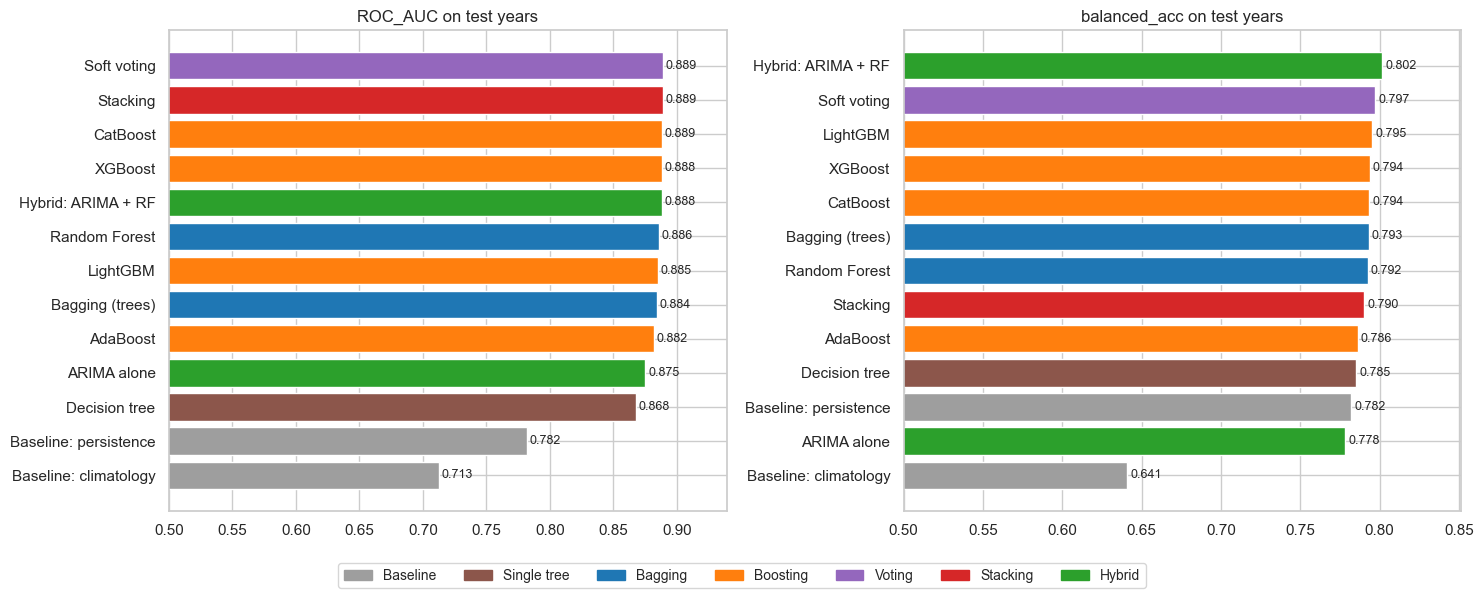

In [19]:
GROUP_COLORS = {"Baseline": "#9e9e9e", "Single tree": "#8c564b", "Bagging": "#1f77b4", "Boosting": "#ff7f0e",
                "Voting": "#9467bd", "Stacking": "#d62728", "Hybrid": "#2ca02c"}
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
for a, metric, lo in [(ax[0], "ROC_AUC", 0.5), (ax[1], "balanced_acc", 0.5)]:
    r = res[metric].dropna().sort_values()
    a.barh(r.index, r.values, color=[GROUP_COLORS[res.loc[i, "group"]] for i in r.index])
    for i, v in enumerate(r.values): a.text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=9)
    a.set_xlim(lo, min(1, r.max() + 0.05)); a.set_title(f"{metric} on test years")
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=c, label=g) for g, c in GROUP_COLORS.items()], loc="lower center", ncol=7, fontsize=10)
plt.tight_layout(rect=[0, 0.06, 1, 1]); plt.savefig("images/model_comparison.png", dpi=120, bbox_inches="tight"); plt.show()

### 6.2 Results by zone

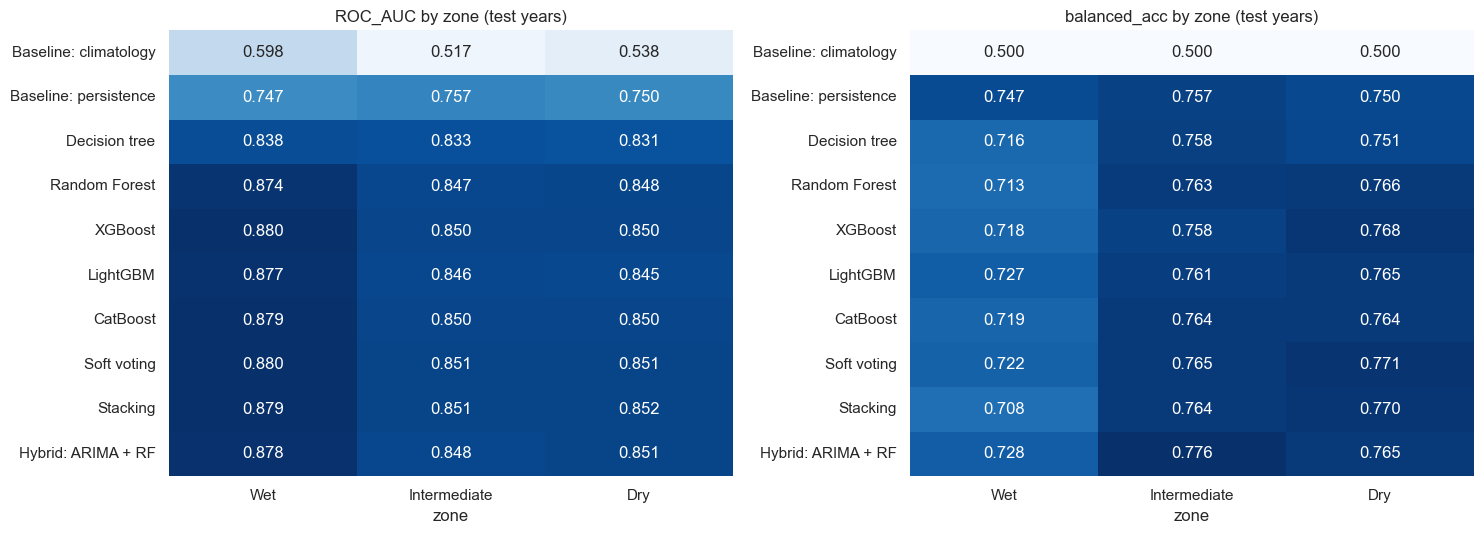

zone
Dry             42%
Intermediate    55%
Wet             80%
Name: rain days, dtype: object

In [20]:
SHOW = ["Baseline: climatology", "Baseline: persistence", "Decision tree", "Random Forest", "XGBoost",
        "LightGBM", "CatBoost", "Soft voting", "Stacking", "Hybrid: ARIMA + RF"]
rows = []
for z in ["Wet", "Intermediate", "Dry"]:
    mask = (test.zone == z).values
    for m in SHOW:
        s = scores(yte[mask], TEST_PROB[m][mask])
        rows.append({"zone": z, "model": m, "rain days": yte[mask].mean(), **s})
by_zone = pd.DataFrame(rows)
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
for a, metric in [(ax[0], "ROC_AUC"), (ax[1], "balanced_acc")]:
    piv = by_zone.pivot(index="model", columns="zone", values=metric).loc[SHOW, ["Wet", "Intermediate", "Dry"]]
    sns.heatmap(piv, annot=True, fmt=".3f", cmap="Blues", ax=a, cbar=False, vmin=0.5, vmax=piv.values.max())
    a.set_title(f"{metric} by zone (test years)"); a.set_ylabel("")
plt.tight_layout(); plt.savefig("images/results_by_zone.png", dpi=120, bbox_inches="tight"); plt.show()
by_zone.groupby("zone")["rain days"].first().map("{:.0%}".format)

### 6.3 ROC curves (main models)

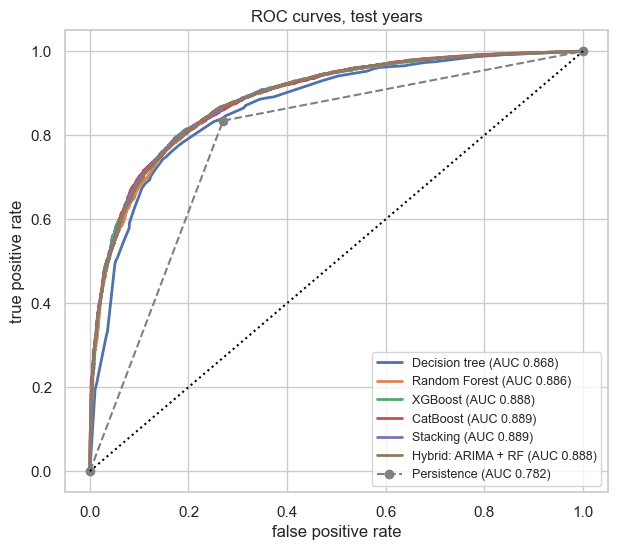

In [21]:
fig, ax = plt.subplots(figsize=(7, 6))
for m in ["Decision tree", "Random Forest", "XGBoost", "CatBoost", "Stacking", "Hybrid: ARIMA + RF"]:
    fpr, tpr, _ = roc_curve(yte, TEST_PROB[m]); ax.plot(fpr, tpr, lw=2, label=f"{m} (AUC {RESULTS[m]['ROC_AUC']:.3f})")
fpr, tpr, _ = roc_curve(yte, TEST_PROB["Baseline: persistence"])
ax.plot(fpr, tpr, "o--", color="grey", label=f"Persistence (AUC {RESULTS['Baseline: persistence']['ROC_AUC']:.3f})")
ax.plot([0, 1], [0, 1], ":", color="black"); ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate")
ax.legend(fontsize=9); ax.set_title("ROC curves, test years"); plt.show()

### 6.4 Light rain (1 mm) vs real rain (5 mm)
The same models and settings are trained again for the 5 mm target.

In [22]:
T5 = "rain_tomorrow_5mm"
y5tr, y5va, y5te = train[T5].astype(int), valid[T5].astype(int), test[T5].astype(int)
def params_of(name): return {k: v for k, v in INFO[name].items() if k != "valid_AUC"}
five = {
    "Baseline: climatology": test.city.map(train.groupby("city")[T5].mean()).values,
    "Baseline: persistence": (test.precipitation_sum >= 5).astype(float).values,
    "Random Forest": RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE, **params_of("Random Forest")),
    "XGBoost": XGBClassifier(n_estimators=400, subsample=0.8, colsample_bytree=0.8, eval_metric="logloss", n_jobs=-1,
                             random_state=RANDOM_STATE, **params_of("XGBoost")),
    "LightGBM": LGBMClassifier(n_estimators=400, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                               random_state=RANDOM_STATE, verbose=-1, **params_of("LightGBM")),
    "CatBoost": CatBoostClassifier(allow_writing_files=False, iterations=500, verbose=0, random_seed=RANDOM_STATE, thread_count=-1, **params_of("CatBoost")),
}
rows = []
for name, m in five.items():
    prob = m if isinstance(m, np.ndarray) else m.fit(Xtr, y5tr).predict_proba(Xte)[:, 1]
    rows.append({"model": name, "target": "5 mm", **scores(y5te, prob)})
    rows.append({"model": name, "target": "1 mm", **scores(yte, TEST_PROB[name])})
cmp = pd.DataFrame(rows).pivot(index="model", columns="target", values=["balanced_acc", "F1", "ROC_AUC"]).loc[list(five)]
print(f"rain days in test years: 1 mm or more {yte.mean():.0%}, 5 mm or more {y5te.mean():.0%}")
cmp.round(3)

rain days in test years: 1 mm or more 62%, 5 mm or more 31%


balanced_acc            F1        ROC_AUC       
target                        1 mm   5 mm   1 mm   5 mm    1 mm   5 mm
model                                                                 
Baseline: climatology        0.641  0.551  0.745  0.268   0.713  0.656
Baseline: persistence        0.782  0.758  0.834  0.667   0.782  0.758
Random Forest                0.792  0.764  0.851  0.677   0.886  0.867
XGBoost                      0.794  0.771  0.851  0.684   0.888  0.869
LightGBM                     0.795  0.769  0.852  0.682   0.885  0.867
CatBoost                     0.794  0.770  0.851  0.685   0.889  0.872

### 6.5 Hybrid: Random Forest + ANN for rainfall amount (regression)
The same features are used to predict *how much* it will rain tomorrow (mm). The target is log(1 + mm) because a few
days have very large values; results are shown back in mm.
- Random Forest regressor
- ANN: a multi-layer perceptron (2 hidden layers, features standardised using the training years)
- Hybrid RF + ANN: a linear regression learns how to combine the two, trained on the validation years

In [23]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

ltr, lva = np.log1p(train.rain_tomorrow_mm), np.log1p(valid.rain_tomorrow_mm)
mm_te = test.rain_tomorrow_mm.values

def reg_scores(pred_mm):
    return {"MAE (mm)": mean_absolute_error(mm_te, pred_mm), "RMSE (mm)": np.sqrt(mean_squared_error(mm_te, pred_mm)),
            "R2": r2_score(mm_te, pred_mm)}

t0 = time.time()
rf_reg = RandomForestRegressor(n_estimators=300, max_depth=15, min_samples_leaf=5, max_features=0.5, n_jobs=-1,
                               random_state=RANDOM_STATE).fit(Xtr, ltr)
rf_reg_s = time.time() - t0
t0 = time.time()
ann = make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(64, 32), alpha=1e-3, early_stopping=True,
                                                   max_iter=300, random_state=RANDOM_STATE)).fit(Xtr, ltr)
ann_s = time.time() - t0
comb = LinearRegression().fit(np.column_stack([rf_reg.predict(Xva), ann.predict(Xva)]), lva)
P_te = np.column_stack([rf_reg.predict(Xte), ann.predict(Xte)])

REG = {
    "Baseline: persistence (today's rain)": reg_scores(test.precipitation_sum.values),
    "Baseline: climatology (city mean)": reg_scores(test.city.map(train.groupby("city").rain_tomorrow_mm.mean()).values),
    "Random Forest": reg_scores(np.expm1(P_te[:, 0])),
    "ANN (MLP)": reg_scores(np.expm1(P_te[:, 1])),
    "Hybrid: RF + ANN": reg_scores(np.expm1(comb.predict(P_te))),
}
print(f"training time: RF {rf_reg_s:.0f} s, ANN {ann_s:.0f} s | hybrid weights RF {comb.coef_[0]:.2f}, ANN {comb.coef_[1]:.2f}")
pd.DataFrame(REG).T.round(3)

training time: RF 18 s, ANN 17 s | hybrid weights RF 0.55, ANN 0.47


,MAE (mm),RMSE (mm),R2
Baseline: persistence (today's rain),5.326,12.268,0.061
Baseline: climatology (city mean),6.681,12.422,0.037
Random Forest,4.413,10.686,0.287
ANN (MLP),4.371,10.336,0.333
Hybrid: RF + ANN,4.339,10.378,0.328


### 6.6 Choosing the decision threshold
The models give a probability of rain. By default "rain" is predicted when it is 0.5 or more. In the wet zone it
rains on most days, so 0.5 makes the model say "rain" too often. Here the threshold is chosen on the validation
years (best balanced accuracy), once for all cities and once for each zone, and then checked on the test years.
Model: soft voting.

In [24]:
def best_threshold(y, p):
    grid = np.round(np.arange(0.20, 0.81, 0.01), 2)
    return grid[int(np.argmax([balanced_accuracy_score(y, (p >= t).astype(int)) for t in grid]))]

p_val = np.mean([MODELS[m].predict_proba(Xva)[:, 1] for m in VOTE], axis=0)
p_test = TEST_PROB["Soft voting"]
t_all = best_threshold(yva, p_val)
ZONE_THR = {}
rows = []
for z in ["Wet", "Intermediate", "Dry", "All"]:
    mv = np.ones(len(yva), bool) if z == "All" else (valid.zone == z).values
    mt = np.ones(len(yte), bool) if z == "All" else (test.zone == z).values
    t_z = t_all if z == "All" else best_threshold(yva[mv], p_val[mv])
    if z != "All": ZONE_THR[z] = float(t_z)
    rows.append({"zone": z, "threshold 0.5": balanced_accuracy_score(yte[mt], (p_test[mt] >= 0.5).astype(int)),
                 f"one threshold ({t_all:.2f})": balanced_accuracy_score(yte[mt], (p_test[mt] >= t_all).astype(int)),
                 "zone threshold": t_z,
                 "with zone threshold": balanced_accuracy_score(yte[mt], (p_test[mt] >= t_z).astype(int)),
                 "persistence": balanced_accuracy_score(yte[mt], (test.precipitation_sum.values[mt] >= 1).astype(int))})
thr_table = pd.DataFrame(rows).set_index("zone")
z_pred = (p_test >= test.zone.map(ZONE_THR).values).astype(int)
print(f"all cities, zone thresholds: balanced accuracy {balanced_accuracy_score(yte, z_pred):.3f}, F1 {f1_score(yte, z_pred):.3f}")
thr_table.round(3)

all cities, zone thresholds: balanced accuracy 0.791, F1 0.818


,threshold 0.5,one threshold (0.69),zone threshold,with zone threshold,persistence
zone,,,,,
Wet,0.722,0.784,0.80,0.800,0.747
Intermediate,0.765,0.762,0.67,0.762,0.757
Dry,0.771,0.720,0.46,0.770,0.750
All,0.797,0.807,0.69,0.807,0.782


### 6.7 Results by year
The same models, scored separately for each test year (2026 runs to mid-November).

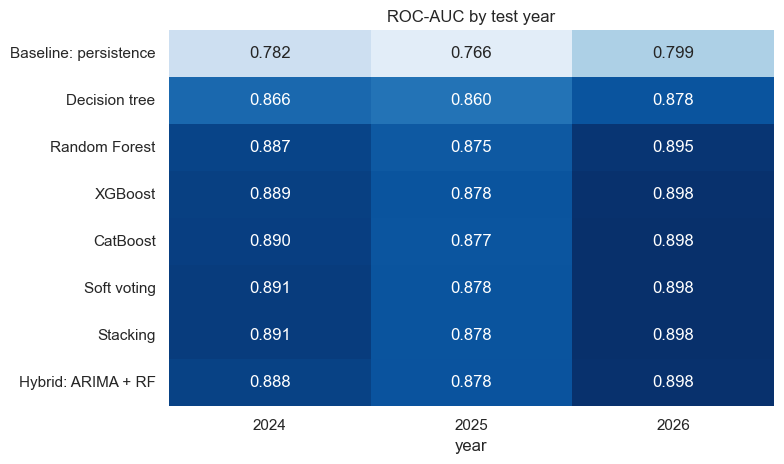

share of rain days: {2024: '62%', 2025: '64%', 2026: '59%'}


In [25]:
YEAR_MODELS = ["Baseline: persistence", "Decision tree", "Random Forest", "XGBoost", "CatBoost", "Soft voting", "Stacking",
               "Hybrid: ARIMA + RF"]
years = test.date.dt.year.values
rows = []
for yr in sorted(set(years)):
    m = years == yr
    for name in YEAR_MODELS:
        rows.append({"year": yr, "model": name, "ROC_AUC": roc_auc_score(yte[m], TEST_PROB[name][m]),
                     "rain days": yte[m].mean()})
by_year = pd.DataFrame(rows)
piv_year = by_year.pivot(index="model", columns="year", values="ROC_AUC").loc[YEAR_MODELS]
fig, ax = plt.subplots(figsize=(8, 4.8))
sns.heatmap(piv_year, annot=True, fmt=".3f", cmap="Blues", cbar=False, ax=ax, vmin=0.75)
ax.set_title("ROC-AUC by test year"); ax.set_ylabel(""); plt.tight_layout()
plt.savefig("images/results_by_year.png", dpi=120, bbox_inches="tight"); plt.show()
print("share of rain days:", by_year.groupby("year")["rain days"].first().map("{:.0%}".format).to_dict())

### 6.8 Bagging vs boosting vs stacking (lecture ideas and what happened here)

| | Bagging (Random Forest, Bagging) | Boosting (XGBoost, LightGBM, CatBoost, AdaBoost) | Stacking |
|---|---|---|---|
| Base models | many trees of the same kind | many small trees of the same kind | different models (RF, Bagging, XGBoost, LightGBM, CatBoost) |
| How they are trained | independently, each on a bootstrap sample (in parallel) | one after another, each fixing the errors of the earlier ones | base models first, then a meta-model on their predictions |
| How they are combined | average of the trees | weighted sum of the trees | a logistic regression learns the weights (trained on the validation years) |
| Mainly reduces | variance | bias | both, if the base models make different errors |
| Test ROC-AUC here | Random Forest 0.886, Bagging 0.884 | CatBoost 0.889, XGBoost 0.888, LightGBM 0.885, AdaBoost 0.882 | 0.889 |
| Seen in this project | OOB accuracy 0.816 vs test 0.811; the score barely changes after about 50 to 100 trees (5.3b) | small trees with a low learning rate were chosen on the validation years | gave most weight to Random Forest and CatBoost; only a tiny gain over its best base model |

### 6.9 Can the chance of rain be trusted? (calibration)
The dashboard shows a chance of rain, so the probabilities themselves should be right, not only the ranking.
The test days are put into 10 groups by their predicted chance, and for each group the predicted chance is
compared with how often it really rained. A perfect model sits on the diagonal. The Brier score is the mean squared
error of the probabilities (lower is better).

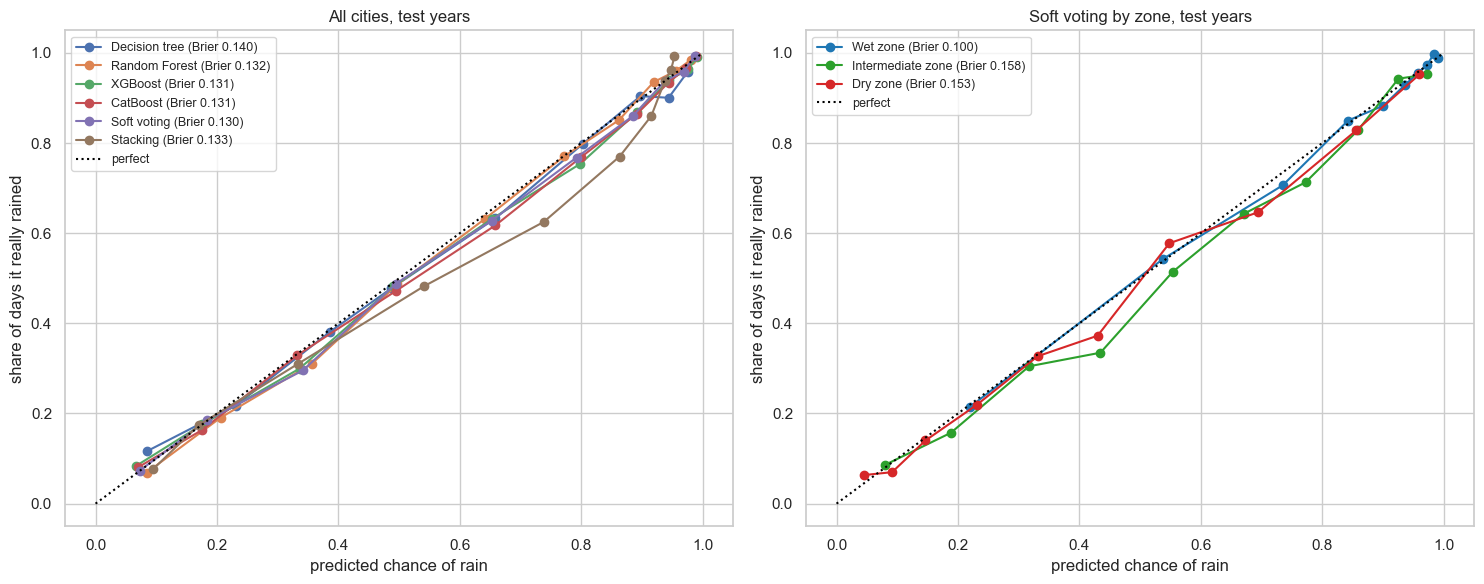

,days,mean_predicted,really_rained
band,,,
0 to 20%,1552,0.106,0.108
20 to 40%,1172,0.303,0.276
40 to 60%,1208,0.499,0.474
60 to 80%,1321,0.707,0.678
80 to 100%,4188,0.933,0.928


In [26]:
from sklearn.calibration import calibration_curve
CAL_MODELS = ["Decision tree", "Random Forest", "XGBoost", "CatBoost", "Soft voting", "Stacking"]
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
for m in CAL_MODELS:
    frac, mean = calibration_curve(yte, TEST_PROB[m], n_bins=10, strategy="quantile")
    ax[0].plot(mean, frac, marker="o", label=f"{m} (Brier {brier_score_loss(yte, TEST_PROB[m]):.3f})")
ax[0].set_title("All cities, test years")
for z, col in [("Wet", "#1f77b4"), ("Intermediate", "#2ca02c"), ("Dry", "#d62728")]:
    mz = (test.zone == z).values
    frac, mean = calibration_curve(yte[mz], TEST_PROB["Soft voting"][mz], n_bins=10, strategy="quantile")
    ax[1].plot(mean, frac, marker="o", color=col,
               label=f"{z} zone (Brier {brier_score_loss(yte[mz], TEST_PROB['Soft voting'][mz]):.3f})")
ax[1].set_title("Soft voting by zone, test years")
for a in ax:
    a.plot([0, 1], [0, 1], ":", color="black", label="perfect")
    a.set_xlabel("predicted chance of rain"); a.set_ylabel("share of days it really rained"); a.legend(fontsize=9)
plt.tight_layout(); plt.savefig("images/calibration.png", dpi=120, bbox_inches="tight"); plt.show()

bands = pd.cut(TEST_PROB["Soft voting"], [0, 0.2, 0.4, 0.6, 0.8, 1.0], include_lowest=True,
               labels=["0 to 20%", "20 to 40%", "40 to 60%", "60 to 80%", "80 to 100%"])
pd.DataFrame({"band": bands, "predicted": TEST_PROB["Soft voting"], "rained": yte}).groupby("band", observed=True).agg(
    days=("rained", "size"), mean_predicted=("predicted", "mean"), really_rained=("rained", "mean")).round(3)

### 6.10 Are the differences between the models real? (bootstrap)
Many models score within a few thousandths of each other. To see if a gap is real or just luck in the test days,
the test days are resampled 1,000 times with replacement and every model is scored on each sample. Whole days
are resampled (all 9 cities together), because cities on the same day share the same weather. Each model is also
compared with soft voting on the same samples: if the 95% interval of the difference includes 0, the two models
cannot really be told apart.

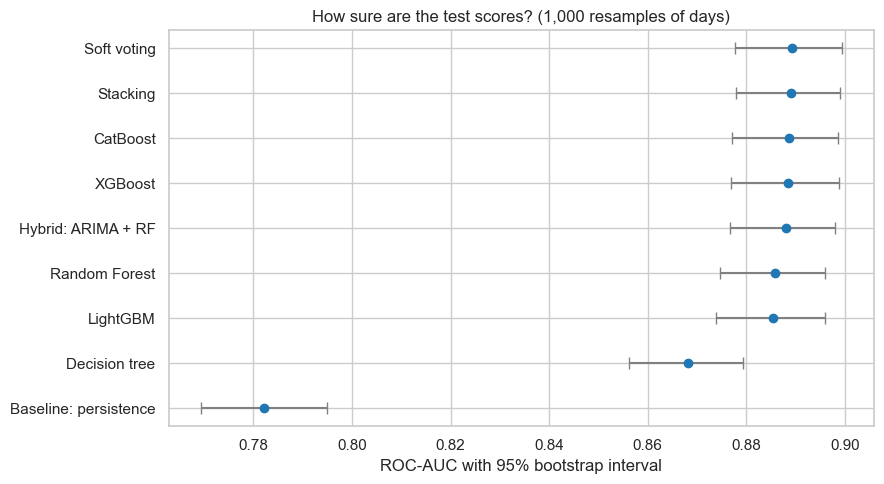

,ROC_AUC,95% low,95% high,vs soft voting,diff low,diff high,clearly different?
model,,,,,,,
Baseline: persistence,0.782,0.769,0.795,-0.107,-0.114,-0.100,yes
Decision tree,0.868,0.856,0.879,-0.021,-0.025,-0.017,yes
LightGBM,0.885,0.874,0.896,-0.004,-0.005,-0.002,yes
Random Forest,0.886,0.875,0.896,-0.003,-0.005,-0.001,yes
Hybrid: ARIMA + RF,0.888,0.877,0.898,-0.001,-0.003,0.001,no
XGBoost,0.888,0.877,0.899,-0.001,-0.002,0.000,no
CatBoost,0.889,0.877,0.899,-0.001,-0.002,0.000,no
Stacking,0.889,0.878,0.899,-0.000,-0.001,0.001,no
Soft voting,0.889,0.878,0.899,0.000,0.000,0.000,-


In [27]:
BOOT_MODELS = ["Baseline: persistence", "Decision tree", "Random Forest", "XGBoost", "LightGBM", "CatBoost",
               "Soft voting", "Stacking", "Hybrid: ARIMA + RF"]
rng = np.random.default_rng(42)
day_codes, day_index = np.unique(test.date.values, return_inverse=True)
rows_of_day = [np.flatnonzero(day_index == d) for d in range(len(day_codes))]
N_BOOT = 1000
y_test = yte.values
boot = {m: np.empty(N_BOOT) for m in BOOT_MODELS}
for b in range(N_BOOT):
    boot_idx = np.concatenate([rows_of_day[d] for d in rng.integers(0, len(rows_of_day), len(rows_of_day))])
    for m in BOOT_MODELS:
        boot[m][b] = roc_auc_score(y_test[boot_idx], TEST_PROB[m][boot_idx])

ref = boot["Soft voting"]
boot_rows = []
for m in BOOT_MODELS:
    diff = boot[m] - ref
    lo_d, hi_d = np.percentile(diff, [2.5, 97.5])
    boot_rows.append({"model": m, "ROC_AUC": RESULTS[m]["ROC_AUC"],
                 "95% low": np.percentile(boot[m], 2.5), "95% high": np.percentile(boot[m], 97.5),
                 "vs soft voting": RESULTS[m]["ROC_AUC"] - RESULTS["Soft voting"]["ROC_AUC"],
                 "diff low": lo_d, "diff high": hi_d,
                 "clearly different?": "-" if m == "Soft voting" else ("no" if lo_d <= 0 <= hi_d else "yes")})
boot_table = pd.DataFrame(boot_rows).set_index("model").sort_values("ROC_AUC")

fig, ax = plt.subplots(figsize=(9, 5))
y_pos = np.arange(len(boot_table))
ax.errorbar(boot_table["ROC_AUC"], y_pos,
            xerr=[boot_table["ROC_AUC"] - boot_table["95% low"], boot_table["95% high"] - boot_table["ROC_AUC"]],
            fmt="o", color="#1f77b4", ecolor="grey", capsize=4)
ax.set_yticks(y_pos); ax.set_yticklabels(boot_table.index)
ax.set_xlabel("ROC-AUC with 95% bootstrap interval"); ax.set_title("How sure are the test scores? (1,000 resamples of days)")
plt.tight_layout(); plt.savefig("images/bootstrap_auc.png", dpi=120, bbox_inches="tight"); plt.show()
boot_table.style.format({c: "{:.3f}" for c in ["ROC_AUC", "95% low", "95% high", "vs soft voting", "diff low", "diff high"]})

### 6.11 Confusion matrices by zone
Soft voting with the zone cut-offs from 6.6 (the same rule the dashboard uses). Each box shows the number of
city-days and the share of the true class (row).

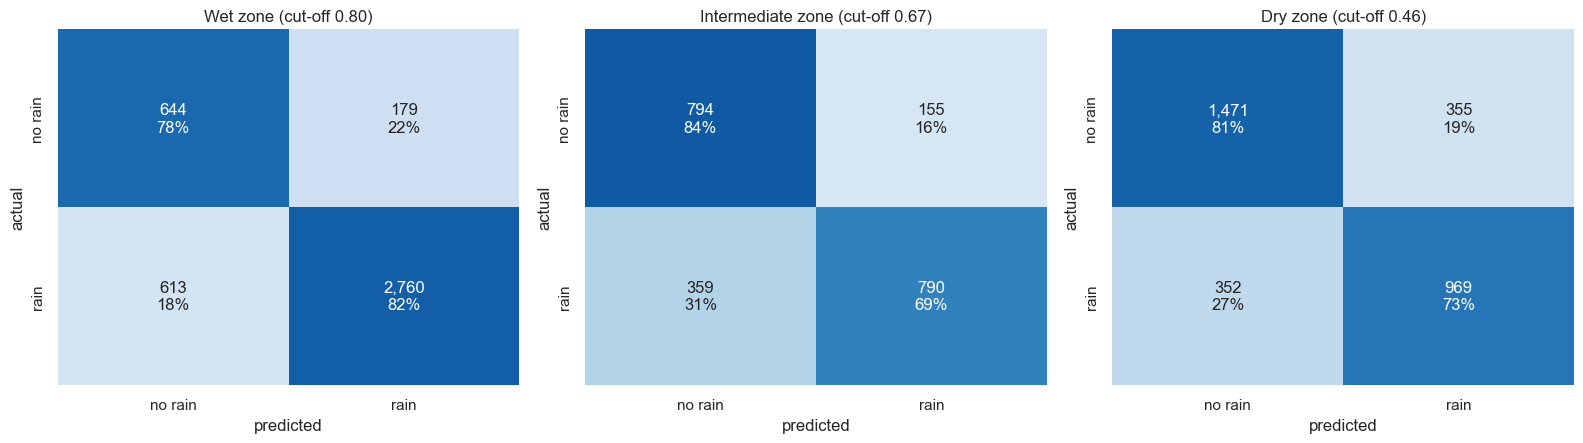

,rain days caught,dry days caught,missed rain days,false alarms
zone,,,,
Wet,0.818,0.783,613,179
Intermediate,0.688,0.837,359,155
Dry,0.734,0.806,352,355


In [28]:
from sklearn.metrics import confusion_matrix
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
cm_rows = []
for a, z in zip(ax, ["Wet", "Intermediate", "Dry"]):
    mz = (test.zone == z).values
    cm = confusion_matrix(yte[mz], z_pred[mz], labels=[0, 1])
    share = cm / cm.sum(axis=1, keepdims=True)
    cell_text = np.array([[f"{cm[i, j]:,}\n{share[i, j]:.0%}" for j in range(2)] for i in range(2)])
    sns.heatmap(share, annot=cell_text, fmt="", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=a,
                xticklabels=["no rain", "rain"], yticklabels=["no rain", "rain"])
    a.set_title(f"{z} zone (cut-off {ZONE_THR[z]:.2f})"); a.set_xlabel("predicted"); a.set_ylabel("actual")
    tn, fp, fn, tp = cm.ravel()
    cm_rows.append({"zone": z, "rain days caught": tp / (tp + fn), "dry days caught": tn / (tn + fp),
                 "missed rain days": fn, "false alarms": fp})
plt.tight_layout(); plt.savefig("images/confusion_by_zone.png", dpi=120, bbox_inches="tight"); plt.show()
pd.DataFrame(cm_rows).set_index("zone").round(3)

## 7. Why do the models predict what they predict?
### 7.1 Built-in feature importance (Random Forest, XGBoost, CatBoost)
One-hot columns are added together so that "city", "season" and "zone" each appear once.

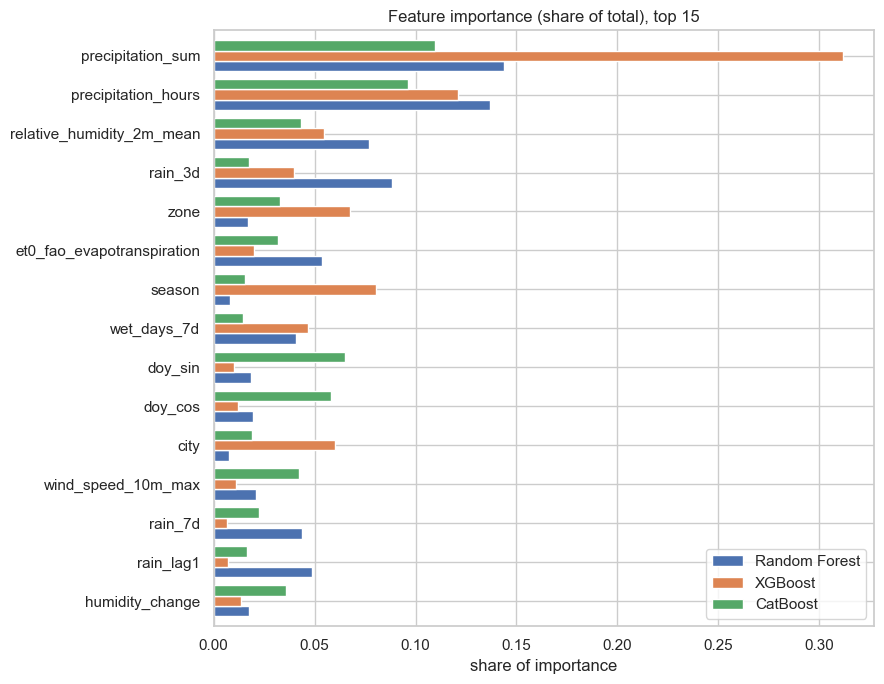

In [29]:
def grouped(series):
    g = series.copy()
    g.index = [("city" if i.startswith("city_") else "season" if i.startswith("season_") else
                "zone" if i.startswith("zone_") else i) for i in g.index]
    g = g.groupby(level=0).sum()
    return g / g.sum()

imp = pd.DataFrame({
    "Random Forest": grouped(pd.Series(MODELS["Random Forest"].feature_importances_, index=FEATURES)),
    "XGBoost": grouped(pd.Series(MODELS["XGBoost"].feature_importances_, index=FEATURES)),
    "CatBoost": grouped(pd.Series(MODELS["CatBoost"].get_feature_importance(), index=FEATURES)),
})
top = imp.mean(axis=1).sort_values(ascending=False).index[:15]
imp.loc[top[::-1]].plot.barh(figsize=(9, 7), width=0.8)
plt.title("Feature importance (share of total), top 15"); plt.xlabel("share of importance"); plt.tight_layout(); plt.show()

### 7.2 Permutation importance (CatBoost, test years)
Each feature is shuffled in turn; the drop in ROC-AUC shows how much the model really depends on it.

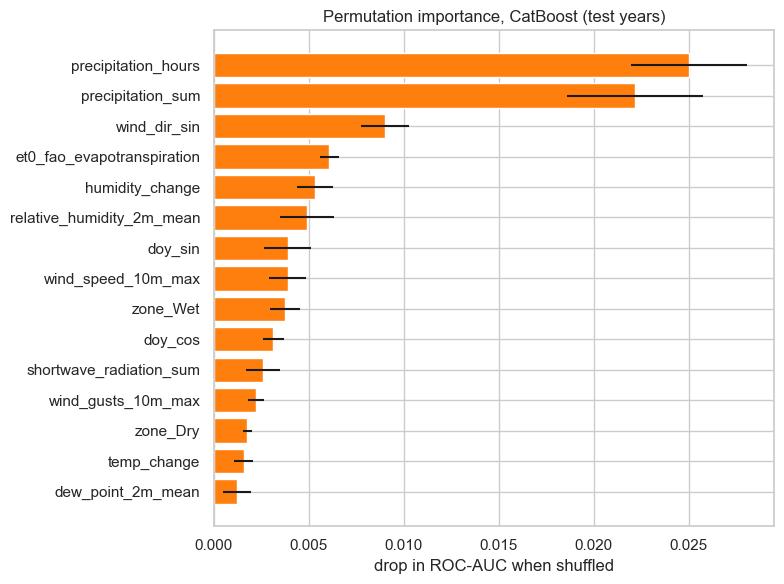

In [30]:
from sklearn.inspection import permutation_importance
sample = test.sample(3000, random_state=RANDOM_STATE)
pi = permutation_importance(MODELS["CatBoost"], sample[FEATURES], sample[TARGET].astype(int), scoring="roc_auc",
                            n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
perm = pd.Series(pi.importances_mean, index=FEATURES).sort_values(ascending=False).head(15)
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(perm.index[::-1], perm.values[::-1], xerr=pd.Series(pi.importances_std, index=FEATURES)[perm.index[::-1]], color="#ff7f0e")
ax.set_xlabel("drop in ROC-AUC when shuffled"); ax.set_title("Permutation importance, CatBoost (test years)"); plt.tight_layout(); plt.show()

### 7.3 SHAP values (CatBoost)
SHAP shows, for every single prediction, how much each feature pushed the chance of rain up (red side) or down.

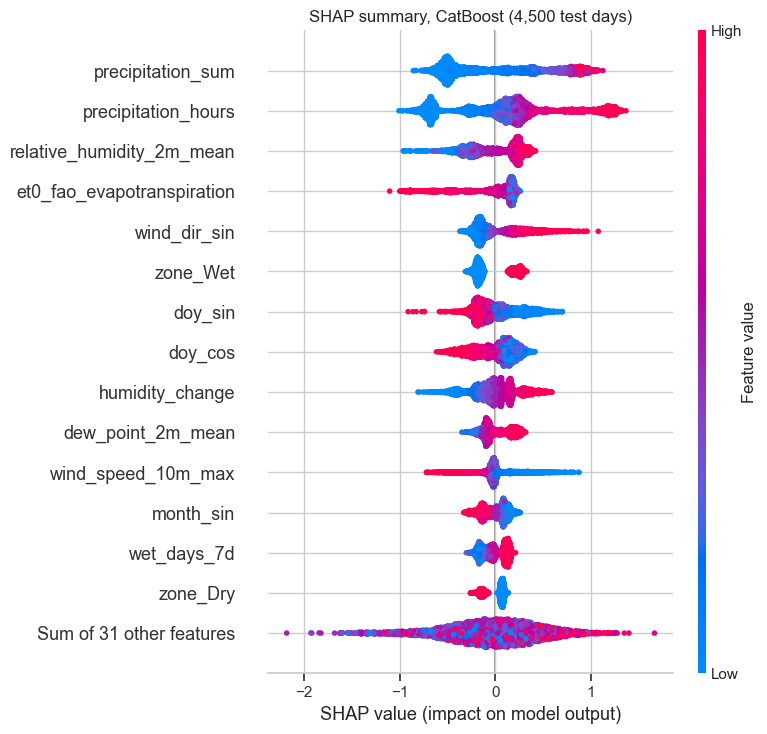

In [31]:
import shap
explainer = shap.TreeExplainer(MODELS["CatBoost"])
shap_sample = test.groupby("zone", group_keys=False).apply(lambda d: d.sample(1500, random_state=RANDOM_STATE))
sv = explainer(shap_sample[FEATURES])
shap.plots.beeswarm(sv, max_display=15, show=False)
plt.title("SHAP summary, CatBoost (4,500 test days)"); plt.tight_layout(); plt.savefig("images/shap_summary.png", dpi=120, bbox_inches="tight"); plt.show()

### 7.4 Do the zones depend on different features?
Mean absolute SHAP value per feature, separately for each zone (one-hot columns added together).

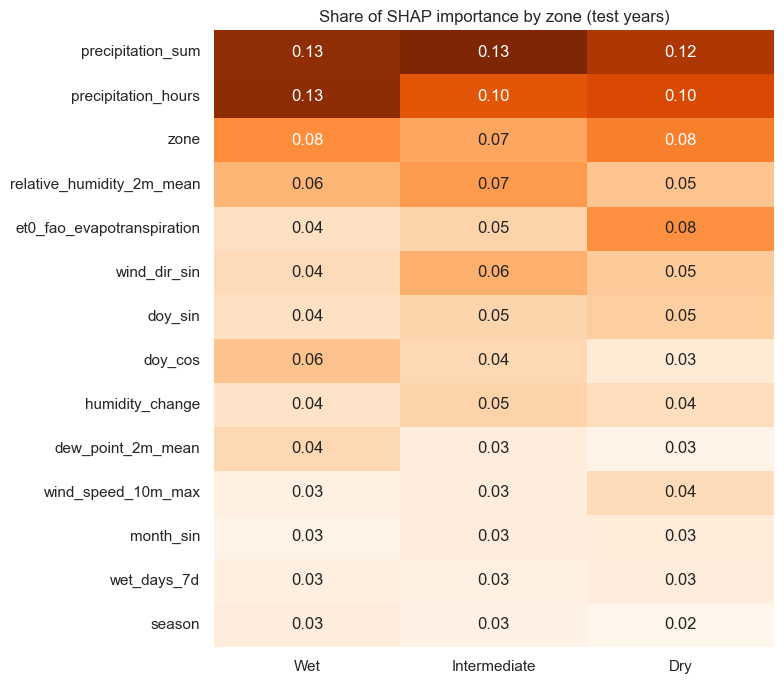

,rank in Wet,rank in Intermediate,rank in Dry
precipitation_sum,2,1,1
precipitation_hours,1,2,2
zone,3,4,3
relative_humidity_2m_mean,4,3,5
et0_fao_evapotranspiration,9,7,4
wind_dir_sin,7,5,6
doy_sin,8,8,7
doy_cos,5,9,10
humidity_change,10,6,9
dew_point_2m_mean,6,11,13


In [32]:
abs_sv = pd.DataFrame(np.abs(sv.values), columns=FEATURES, index=shap_sample.index)
zone_imp = pd.DataFrame({z: grouped(abs_sv[shap_sample.zone == z].mean()) for z in ["Wet", "Intermediate", "Dry"]})
top_z = zone_imp.mean(axis=1).sort_values(ascending=False).index[:14]
fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(zone_imp.loc[top_z], annot=True, fmt=".2f", cmap="Oranges", cbar=False, ax=ax)
ax.set_title("Share of SHAP importance by zone (test years)"); plt.tight_layout(); plt.savefig("images/shap_by_zone.png", dpi=120, bbox_inches="tight"); plt.show()
rank = zone_imp.rank(ascending=False).loc[top_z].astype(int)
rank.columns = [f"rank in {c}" for c in rank.columns]
rank

### 7.5 How the two most important features change the prediction

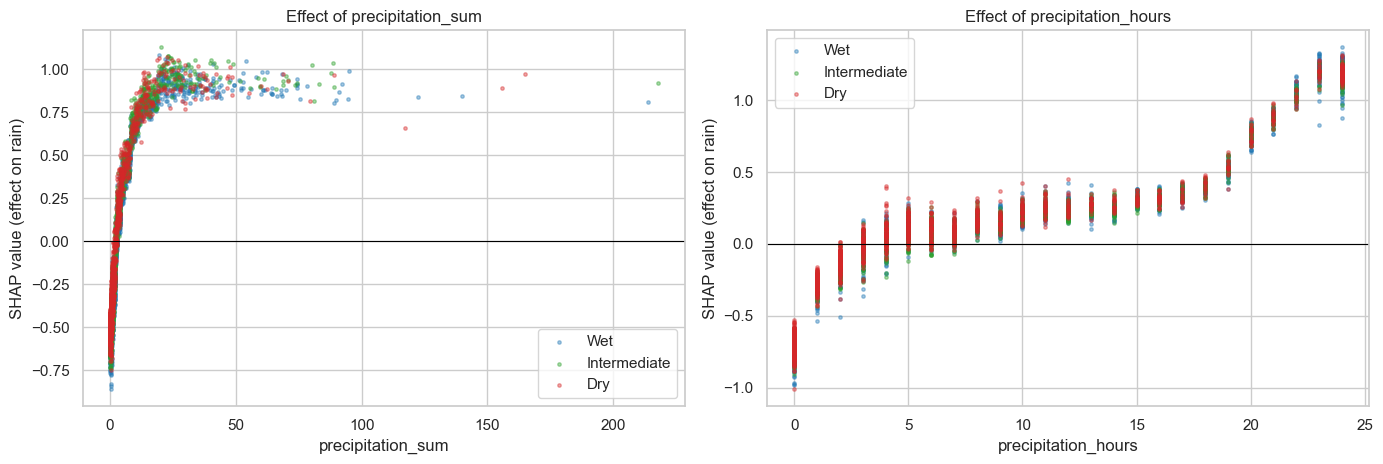

In [33]:
top2 = [f for f in abs_sv.mean().sort_values(ascending=False).index if not f.startswith(("city_", "zone_", "season_"))][:2]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
for a, f in zip(ax, top2):
    j = FEATURES.index(f)
    for z in ["Wet", "Intermediate", "Dry"]:
        m = (shap_sample.zone == z).values
        a.scatter(shap_sample[f].values[m], sv.values[m, j], s=6, alpha=0.4, color=ZONE_COLORS[z], label=z)
    a.axhline(0, color="black", lw=0.8); a.set_xlabel(f); a.set_ylabel("SHAP value (effect on rain)"); a.legend()
    a.set_title(f"Effect of {f}")
plt.tight_layout(); plt.show()

### 7.6 One prediction explained
The day in the test years with the strongest "rain" prediction that turned out wrong (it did not rain), to see why the model was fooled.

Ratnapura, 2024-09-30: predicted chance of rain 100%, actual rain next day 0.6 mm


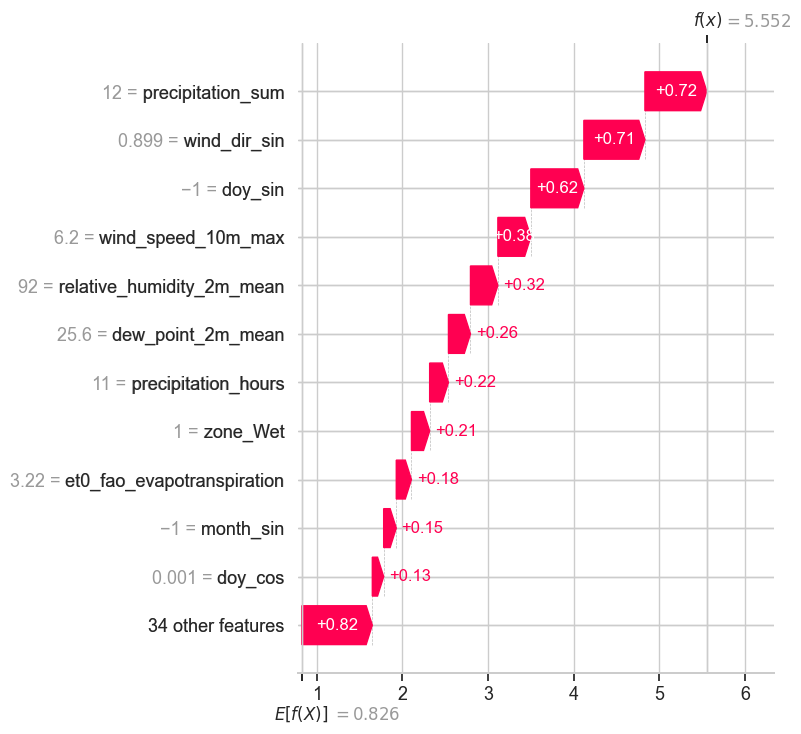

In [34]:
p_cat = TEST_PROB["CatBoost"]
wrong = np.where((p_cat >= 0.5) & (yte.values == 0))[0]
k = wrong[np.argmax(p_cat[wrong])]
row = test.iloc[[k]]
print(f"{row.city.iloc[0]}, {row.date.iloc[0].date()}: predicted chance of rain {p_cat[k]:.0%}, "
      f"actual rain next day {row.rain_tomorrow_mm.iloc[0]:.1f} mm")
shap.plots.waterfall(explainer(row[FEATURES])[0], max_display=12, show=False)
plt.tight_layout(); plt.show()

### 7.7 Where do the models do well or badly? (season and zone)
ROC-AUC of soft voting in every zone and monsoon season (test years).

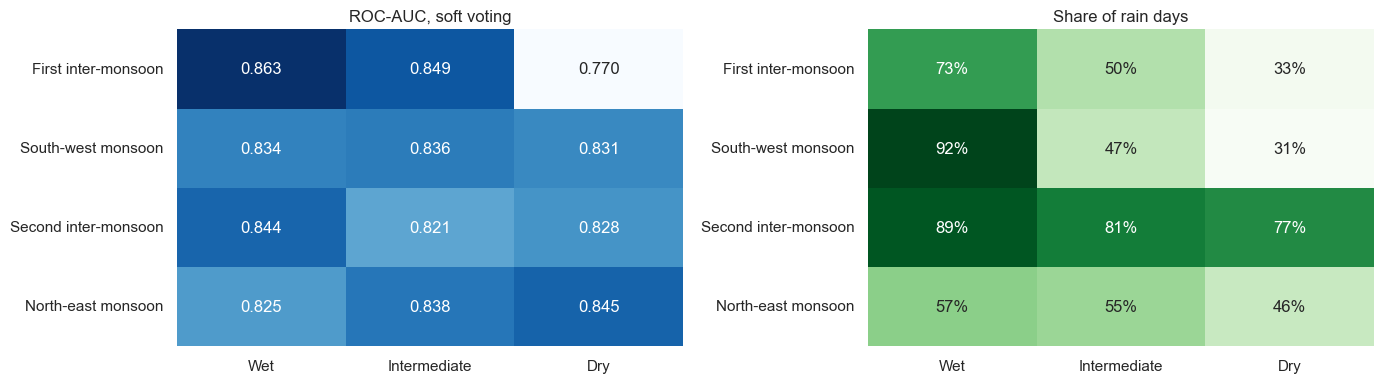

In [35]:
from src.features import SEASONS
grid = pd.DataFrame(index=SEASONS, columns=["Wet", "Intermediate", "Dry"], dtype=float)
share = grid.copy()
for s_ in SEASONS:
    for z in grid.columns:
        m = ((test.season == s_) & (test.zone == z)).values
        grid.loc[s_, z] = roc_auc_score(yte[m], TEST_PROB["Soft voting"][m])
        share.loc[s_, z] = yte[m].mean()
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.heatmap(grid, annot=True, fmt=".3f", cmap="Blues", cbar=False, ax=ax[0]); ax[0].set_title("ROC-AUC, soft voting")
sns.heatmap(share, annot=True, fmt=".0%", cmap="Greens", cbar=False, ax=ax[1]); ax[1].set_title("Share of rain days")
plt.tight_layout(); plt.show()

## 8. Discussion
### 8.1 Answers to my research questions
**RQ1, best ensemble:** every ensemble did much better than the simple guesses (ROC-AUC 0.88 to 0.89, compared to
0.78 for persistence and 0.71 for climatology) and also better than a single decision tree (0.868). The best were
CatBoost, soft voting and stacking (0.889), but Random Forest (0.886) was very close. So my guess that boosting would
be best with only a small difference was mostly right. The bootstrap check (6.10) shows how small the gaps are:
CatBoost, XGBoost, stacking and the ARIMA + RF hybrid cannot be told apart from soft voting, and soft voting is only
clearly ahead of Random Forest and LightGBM, by 0.003 to 0.004. Soft voting also gave the most trustworthy chances
(lowest Brier score, 0.130), while stacking was over-confident at high chances (6.9). This is why the dashboard uses
soft voting.

**RQ2, zones:** by ROC-AUC the wet zone was the easiest (0.88), while the intermediate and dry zones were about the
same (0.85). I expected the intermediate zone to be the hardest, so I was only partly right. The hardest case was the
dry zone in the first inter-monsoon (0.770), probably because rain at that time comes from sudden thunderstorms.
With the zone cut-offs, the intermediate zone missed the most rain days (31%, against 18% in the wet zone and 27% in
the dry zone, 6.11).

**RQ3, 1 mm vs 5 mm:** 5 mm was harder to predict (ROC-AUC 0.87 vs 0.89, F1 0.68 vs 0.85), because days with heavy
rain are fewer. The models still beat the simple guesses.

**RQ4, hybrids:** adding the ARIMA forecast helped Random Forest a little (balanced accuracy 0.792 to 0.802,
the best of all models). ARIMA alone also got 0.875, so the seasonal pattern is useful. For rainfall amount, RF + ANN gave the lowest error (MAE 4.34 mm), but the
ANN alone was about the same. Predicting the amount is much harder than predicting rain or no rain (R2 only 0.33).

Choosing a separate threshold for each zone raised the wet zone balanced accuracy from 0.72 to 0.80.

### 8.2 Strengths and limitations of tree ensembles (tabular vs image / text data)
**Strengths on tabular data:** they handle many different kinds of features together, need no scaling, find
non-linear relationships, train fast on a normal laptop CPU and can be explained with SHAP. Bagging lowers variance
and boosting lowers bias.

**Limitations:** in images and text the meaning is in the patterns between pixels or words. Trees cannot learn these
patterns by themselves, so CNNs or transformers work better there (for example on satellite cloud images). Trees also
cannot predict well outside the values seen in training (for example record rainfall). Ensembles can be large (my
Random Forest file is 27 MB), and time patterns had to be made by hand as lag features.

### 8.3 Limitations of this project
- The data is ERA5 reanalysis, not weather station data. Each value is for a ~25 km grid cell and has a drizzle bias.
  The Colombo grid point (7.0, 80.0) is not right on the coast.
- The live data in the dashboard comes from forecast models, while the training data is ERA5, so there can be small
  differences.
- Only 9 cities, with one grid point each.
- With daily data I cannot see the time of day when it rains, and some errors are near misses just under 1 mm.
- The test period is only about 3 years, the validation years were wetter than normal and the hyper-parameter grids
  were small.

### 8.4 Conclusion
Ensemble models predict tomorrow's rain much better than simple guesses, but the differences between boosting,
bagging, voting and stacking are small, and most of them are within chance (6.10). The chances given by soft voting
match how often it really rained, so they can be shown to users as they are (6.9). The zone matters: the wet zone was the easiest and the dry zone in the first
inter-monsoon was the hardest, and choosing a threshold for each zone is worth doing. For my final year project on
Kelani flood early warning, a model like this could help to give an early warning of heavy rain. In future I would
like to try station data, more cities, satellite or radar images with a CNN, and LSTM models.

### 8.5 Related work
- De Silva, M. T. & Hornberger, G. M. (2019). Identifying El Niño-Southern Oscillation influences on rainfall with classification models: implications for water resource management of Sri Lanka. *Hydrology and Earth System Sciences*, 23, 1905-1929.
- University of Moratuwa study comparing HEC-HMS with ANN, LSTM, Random Forest and XGBoost for streamflow in the Kelani and Malwathu Oya basins (dl.lib.uom.lk).
- Hybrid models in the literature often let ARIMA/SARIMA model the linear and seasonal part and a machine learning model the rest, e.g. SARIMAX-RF for monthly rainfall (*Jurnal Gaussian*) and hybrid precipitation models in *Water Resources Management* (2023).
- Open-Meteo Historical Weather API documentation; ERA5 reanalysis (ECMWF / Copernicus).

## 9. Final models for the dashboard
The chosen settings are trained again on all years (2010 to Nov 2026) and saved for the Streamlit app.

In [36]:
import joblib, json
os.makedirs("models", exist_ok=True)
X_all, y_all = data[FEATURES], data[TARGET].astype(int)
final = {
    "Random Forest": RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE, **params_of("Random Forest")),
    "XGBoost": XGBClassifier(n_estimators=400, subsample=0.8, colsample_bytree=0.8, eval_metric="logloss", n_jobs=-1,
                             random_state=RANDOM_STATE, **params_of("XGBoost")),
    "LightGBM": LGBMClassifier(n_estimators=400, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                               random_state=RANDOM_STATE, verbose=-1, **params_of("LightGBM")),
    "CatBoost": CatBoostClassifier(allow_writing_files=False, iterations=500, verbose=0, random_seed=RANDOM_STATE, thread_count=-1, **params_of("CatBoost")),
}
for name, m in final.items():
    m.fit(X_all, y_all)

# ARIMA on all years for each city, then the hybrid Random Forest
arima_params, parts = {}, []
for city in CITIES:
    g = raw[raw.city == city].sort_values("date").reset_index(drop=True)
    y, X = np.log1p(g.precipitation_sum.values), fourier(g.date)
    res_all = SARIMAX(y, exog=X, order=(2, 0, 1), trend="c").fit(disp=False)
    arima_params[city] = res_all.params.tolist()
    g["arima_tomorrow"] = np.r_[res_all.fittedvalues[1:], np.nan]
    parts.append(g[["city", "date", "arima_tomorrow"]])
d_all = data.merge(pd.concat(parts), on=["city", "date"], how="left")
final["Hybrid: ARIMA + RF"] = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE,
                                                     **params_of("Random Forest")).fit(d_all[FEAT_A], d_all[TARGET].astype(int))

# rainfall amount (regression): RF + ANN, combined with the weights learned on the validation years
l_all = np.log1p(data.rain_tomorrow_mm)
final["RF regressor"] = RandomForestRegressor(n_estimators=300, max_depth=15, min_samples_leaf=5, max_features=0.5,
                                              n_jobs=-1, random_state=RANDOM_STATE).fit(X_all, l_all)
final["ANN regressor"] = make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(64, 32), alpha=1e-3,
                                       early_stopping=True, max_iter=300, random_state=RANDOM_STATE)).fit(X_all, l_all)

FILES = {"Random Forest": "random_forest", "XGBoost": "xgboost", "LightGBM": "lightgbm", "CatBoost": "catboost",
         "Hybrid: ARIMA + RF": "hybrid_arima_rf", "RF regressor": "rf_regressor", "ANN regressor": "ann_regressor"}
for name, m in final.items():
    joblib.dump(m, f"models/{FILES[name]}.joblib", compress=3)

coords = raw.groupby("city")[["grid_lat", "grid_lon", "elevation"]].first()
meta = {
    "features": FEATURES, "features_hybrid": FEAT_A, "cities": CITIES, "zone": ZONE, "zone_threshold": ZONE_THR,
    "vote_models": VOTE, "files": FILES,
    "rf_ann_weights": {"intercept": float(comb.intercept_), "rf": float(comb.coef_[0]), "ann": float(comb.coef_[1])},
    "regression_results": {m: {k: round(float(v), 4) for k, v in r.items()} for m, r in REG.items()}, "arima_order": [2, 0, 1], "arima_params": arima_params,
    "city_coords": {c: {"lat": float(r.grid_lat), "lon": float(r.grid_lon), "elevation": float(r.elevation)} for c, r in coords.iterrows()},
    "trained_until": str(data.date.max().date()),
    "test_results": {m: {"group": r["group"], **{k: (None if pd.isna(r[k]) else round(float(r[k]), 4))
                                              for k in ["accuracy", "balanced_acc", "F1", "ROC_AUC", "Brier"]}}
                     for m, r in RESULTS.items()},
    "test_by_zone": by_zone.round(4).to_dict(orient="records"),
    "test_by_season_zone": grid.round(4).to_dict(),
}
json.dump(meta, open("models/model_info.json", "w"), indent=1)
pd.DataFrame({"city": test.city.values, "date": test.date.dt.strftime("%Y-%m-%d").values, "zone": test.zone.values,
              "rain_tomorrow_mm": test.rain_tomorrow_mm.values, "prob_soft_voting": TEST_PROB["Soft voting"].round(4)}
             ).to_csv("data/processed/test_predictions.csv", index=False)
for f in sorted(os.listdir("models")) + ["../data/processed/test_predictions.csv"]:
    print(f"{f:40s} {os.path.getsize(os.path.join('models', f)) / 1e6:6.1f} MB")

ann_regressor.joblib                        0.1 MB
catboost.joblib                             0.3 MB
hybrid_arima_rf.joblib                     26.6 MB
lightgbm.joblib                             0.6 MB
model_info.json                             0.0 MB
random_forest.joblib                       27.2 MB
rf_regressor.joblib                        45.1 MB
xgboost.joblib                              0.2 MB
../data/processed/test_predictions.csv      0.4 MB


## 10. Using the saved models (inference demo)
The saved model files are loaded from `models/` (the same code the dashboard uses, `src/predict.py`) and used to
predict rain for the day after the last day in the data.

In [37]:
from src.predict import load_models, load_era5_history, predict
info_saved, saved = load_models()
history_saved = load_era5_history()
last_day = history_saved.date.max() - pd.Timedelta(days=1)
pred_demo, X_demo = predict(history_saved, info_saved, saved, last_day)

print(f"Inputs: weather up to {last_day.date()} (showing a few of the {X_demo.shape[1]} features)")
display(X_demo[["precipitation_sum", "precipitation_hours", "relative_humidity_2m_mean", "pressure_msl_mean",
                "rain_7d", "wet_days_7d"]].round(1))
print(f"Predictions for {(last_day + pd.Timedelta(days=1)).date()}:")
real_next = history_saved[history_saved.date == last_day + pd.Timedelta(days=1)].set_index("city").precipitation_sum
pred_demo.assign(actual_mm=real_next)[["zone", "Soft voting", "threshold", "rain_tomorrow", "expected_mm", "actual_mm"]].round(2)

Inputs: weather up to 2026-11-14 (showing a few of the 45 features)


,precipitation_sum,precipitation_hours,relative_humidity_2m_mean,pressure_msl_mean,rain_7d,wet_days_7d
city,,,,,,
Anuradhapura,0.6,3.0,86,1012.8,59.1,5.0
Badulla,6.0,9.0,88,1014.4,266.0,6.0
Colombo,0.6,5.0,82,1012.5,228.0,5.0
Galle,0.7,6.0,84,1012.3,139.8,6.0
Jaffna,0.2,2.0,79,1012.7,101.7,5.0
Kandy,3.2,7.0,89,1014.8,151.2,6.0
Nuwara Eliya,6.9,12.0,89,1016.0,226.7,6.0
Ratnapura,1.2,7.0,88,1013.5,284.7,7.0
Trincomalee,0.6,6.0,78,1012.2,99.0,5.0


Predictions for 2026-11-15:


,zone,Soft voting,threshold,rain_tomorrow,expected_mm,actual_mm
city,,,,,,
Anuradhapura,Dry,0.66,0.46,True,3.40,4.1
Badulla,Intermediate,0.57,0.67,False,2.74,0.0
Colombo,Wet,0.57,0.80,False,1.88,0.8
Galle,Wet,0.68,0.80,False,2.73,5.3
Jaffna,Dry,0.60,0.46,True,1.80,1.1
Kandy,Intermediate,0.67,0.67,True,2.70,0.9
Nuwara Eliya,Wet,0.58,0.80,False,3.45,0.9
Ratnapura,Wet,0.53,0.80,False,1.73,0.0
Trincomalee,Dry,0.70,0.46,True,4.18,4.4
